# Hospital Readmissions — Data Cleaning

This notebook cleans the **CMS 2008–2010 Data Entrepreneurs' Synthetic Public Use File (DE-SynPUF), Sample 1**
and builds an analysis-ready table of inpatient admissions labeled with **30-day readmission**.

**Source files** (Kaggle: `anikannal/cms-synthetic-data`):

| File | Grain | Used for |
|---|---|---|
| Beneficiary Summary 2008 / 2009 / 2010 | one row per patient per year | demographics, chronic conditions, coverage |
| Inpatient Claims 2008–2010 | one row per hospital-stay claim | index admissions + readmission target |
| Outpatient Claims 2008–2010 | one row per outpatient visit claim | prior-utilization features |

**Sections**
0. Setup & raw load (everything read as text so nothing is silently mangled)
1. Beneficiary cleaning
2. Inpatient claims cleaning
3. Outpatient claims cleaning
4. Building hospital stays and the 30-day readmission label
5. Data profile: course preprocessing checklist (attribute types, summaries, outliers, redundancy)
6. Saving outputs & cleaning summary

Every step that removes or changes rows is recorded in `cleaning_log`, shown at the end.

In [1]:
import os
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import kagglehub
    path = kagglehub.dataset_download("anikannal/cms-synthetic-data")
else:
    # Running outside Colab: point CMS_DATA_DIR at a folder containing the 5 CSVs
    path = os.environ.get("CMS_DATA_DIR", "archive")

OUTPUT_DIR = os.environ.get("CMS_OUTPUT_DIR", "cleaned_data")
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Data directory:", path)
print("Files:", sorted(os.listdir(path)))

Data directory: C:\Users\ryana\school\CompSci\CSCI 4502 Data Mining\hospital-readmissions\archive
Files: ['DE1_0_2008_Beneficiary_Summary_File_Sample_1.csv', 'DE1_0_2008_to_2010_Inpatient_Claims_Sample_1.csv', 'DE1_0_2008_to_2010_Outpatient_Claims_Sample_1.csv', 'DE1_0_2009_Beneficiary_Summary_File_Sample_1.csv', 'DE1_0_2010_Beneficiary_Summary_File_Sample_1.csv']


### Raw load
All columns are read as **strings** (`dtype=str`). If pandas is left to guess, ID and code columns get turned into
floats — e.g. a physician NPI becomes `3.139084e+09` and dates become `20100312.0`. Reading as text first and then
converting each column on purpose (in the sections below) keeps codes such as ICD-9 `0389` or `V5789` intact.

In [2]:
FILES = {
    "bene_2008": "DE1_0_2008_Beneficiary_Summary_File_Sample_1.csv",
    "bene_2009": "DE1_0_2009_Beneficiary_Summary_File_Sample_1.csv",
    "bene_2010": "DE1_0_2010_Beneficiary_Summary_File_Sample_1.csv",
    "inpatient": "DE1_0_2008_to_2010_Inpatient_Claims_Sample_1.csv",
    "outpatient": "DE1_0_2008_to_2010_Outpatient_Claims_Sample_1.csv",
}

def read_raw(key):
    return pd.read_csv(os.path.join(path, FILES[key]), dtype=str)

raw_bene = {year: read_raw(f"bene_{year}") for year in (2008, 2009, 2010)}
raw_ip = read_raw("inpatient")
raw_op = read_raw("outpatient")

for name, df_ in [("bene_2008", raw_bene[2008]), ("bene_2009", raw_bene[2009]), ("bene_2010", raw_bene[2010]),
                  ("inpatient", raw_ip), ("outpatient", raw_op)]:
    print(f"{name:<11} {df_.shape[0]:>9,} rows x {df_.shape[1]:>3} cols")

bene_2008     116,352 rows x  32 cols
bene_2009     114,538 rows x  32 cols
bene_2010     112,754 rows x  32 cols
inpatient      66,773 rows x  81 cols
outpatient    790,790 rows x  76 cols


### Shared helpers
* `cleaning_log` / `log_step(...)` — records the row count before and after every cleaning step.
* `to_date(...)` — DE-SynPUF stores dates as `YYYYMMDD` text; invalid or blank values become `NaT`.
* `missing_report(...)` — share of missing values per column.

In [3]:
cleaning_log = []

def log_step(table, step, rows_before, rows_after, note=""):
    """Record one cleaning step so the end of the notebook can summarize everything that was done."""
    cleaning_log.append({
        "table": table, "step": step,
        "rows_before": rows_before, "rows_after": rows_after,
        "rows_removed": rows_before - rows_after, "note": note,
    })
    print(f"[{table}] {step}: {rows_before:,} -> {rows_after:,} rows "
          f"({rows_before - rows_after:,} removed){' — ' + note if note else ''}")

def to_date(s):
    return pd.to_datetime(s, format="%Y%m%d", errors="coerce")

def missing_report(df_, top=None):
    rep = (df_.isna().mean().mul(100).round(1)
           .rename("pct_missing").sort_values(ascending=False).to_frame())
    return rep.head(top) if top else rep

STUDY_START = pd.Timestamp("2008-01-01")
STUDY_END = pd.Timestamp("2010-12-31")

## 1. Beneficiary cleaning

The beneficiary summary files describe **who the patients are**: age, sex, race, date of death, which chronic
conditions they were flagged with, and how many months they were covered by Medicare each year. There is one file per
year, so one patient can appear up to three times. We build two tables from them:

* `bene_year` – one row per patient per calendar year (conditions and coverage can change from year to year);
* `bene_static` – one row per patient (birth date, sex, race, death date: things that should *not* change).

For readmission modeling these give us patient-level features (age, comorbidities, ESRD) and tell us whether a patient
died, which matters because a patient who dies cannot be readmitted.

### 1.1 Stack the three yearly files and check the key

We add a `YEAR` column and stack the files. The key of this table must be (`DESYNPUF_ID`, `YEAR`): if a patient had
two rows in the same year, joining claims to patients later would duplicate every claim. We also check that IDs look
like the 16-character codes used everywhere else.

In [4]:
_b = pd.concat([df_.assign(YEAR=yr) for yr, df_ in raw_bene.items()], ignore_index=True)

print("Rows per year:", _b["YEAR"].value_counts().sort_index().to_dict())
print("Distinct patients:", f"{_b['DESYNPUF_ID'].nunique():,}")
print("Duplicate (ID, YEAR) rows:", _b.duplicated(["DESYNPUF_ID", "YEAR"]).sum())
print("IDs that are not 16 hex characters:", (~_b["DESYNPUF_ID"].str.fullmatch(r"[0-9A-F]{16}")).sum())
print("Years present per patient:")
display(_b.groupby("DESYNPUF_ID")["YEAR"].agg(lambda s: "+".join(map(str, sorted(s)))).value_counts().to_frame("patients"))
log_step("bene_year", "stack 2008/2009/2010 files", len(_b), len(_b), "no rows dropped; no duplicate (ID, YEAR)")

Rows per year: {2008: 116352, 2009: 114538, 2010: 112754}


Distinct patients: 116,352
Duplicate (ID, YEAR) rows: 0


IDs that are not 16 hex characters: 0
Years present per patient:


,patients
YEAR,
2008+2009+2010,112754
2008,1814
2008+2009,1784


[bene_year] stack 2008/2009/2010 files: 343,644 -> 343,644 rows (0 removed) — no rows dropped; no duplicate (ID, YEAR)


**What the data shows.** There are no duplicate keys. Every patient appears in 2008, and then in 2009 and 2010
unless they leave the file. We will see in 1.4 that "leaving" means *dying*: the file is a cohort that shrinks
over time, not a sample that gains new patients.

### 1.2 Convert codes to proper types

Everything was read as text, so now we convert each column on purpose:

* **Dates** (`YYYYMMDD`) -> datetime. Blank death dates stay `NaT` (= still alive).
* **Sex** `1/2` -> `M`/`F` and **race** `1/2/3/5` -> `White/Black/Other/Hispanic`, stored as categoricals. Any code
  outside the documented list would become missing and be counted below.
* **ESRD** (end-stage renal disease) `Y`/`0` -> `1`/`0`.
* The 11 chronic-condition flags use CMS's `1 = yes, 2 = no`. A `2` read as a number would look "bigger" than a `1`,
  which is the opposite of what we want, so we recode to `1 = has condition`, `0 = does not`.
* **State / county** are SSA geographic codes, i.e. labels not quantities: kept as zero-padded strings.

Renames (to make later code readable): `BENE_SEX_IDENT_CD` -> `SEX`, `BENE_RACE_CD` -> `RACE`,
`BENE_ESRD_IND` -> `ESRD`. All other column names are left in CMS style.

In [5]:
_SEX_MAP = {"1": "M", "2": "F"}
_RACE_MAP = {"1": "White", "2": "Black", "3": "Other", "5": "Hispanic"}
_CHRONIC = ["SP_ALZHDMTA", "SP_CHF", "SP_CHRNKIDN", "SP_CNCR", "SP_COPD", "SP_DEPRESSN",
            "SP_DIABETES", "SP_ISCHMCHT", "SP_OSTEOPRS", "SP_RA_OA", "SP_STRKETIA"]

by = _b.copy()
by["BENE_BIRTH_DT"] = to_date(by["BENE_BIRTH_DT"])
by["BENE_DEATH_DT"] = to_date(by["BENE_DEATH_DT"])
print("Unparseable birth dates:", by["BENE_BIRTH_DT"].isna().sum(),
      "| death dates that were present but unparseable:",
      (by["BENE_DEATH_DT"].isna() & _b["BENE_DEATH_DT"].notna()).sum())

# unknown codes -> NaN, counted so nothing disappears silently
for _raw_col, _new_col, _mapping in [("BENE_SEX_IDENT_CD", "SEX", _SEX_MAP), ("BENE_RACE_CD", "RACE", _RACE_MAP)]:
    _mapped = by[_raw_col].map(_mapping)
    print(f"{_new_col}: codes outside {list(_mapping)} ->", int(_mapped.isna().sum()))
    by[_new_col] = pd.Categorical(_mapped, categories=list(_mapping.values()))
by = by.drop(columns=["BENE_SEX_IDENT_CD", "BENE_RACE_CD"])

print("ESRD raw values:", by["BENE_ESRD_IND"].value_counts().to_dict())
by["ESRD"] = by["BENE_ESRD_IND"].map({"Y": 1, "0": 0}).astype("int8")
by = by.drop(columns="BENE_ESRD_IND")

for _c in _CHRONIC:
    assert set(by[_c].unique()) <= {"1", "2"}, f"unexpected code in {_c}"
    by[_c] = by[_c].map({"1": 1, "2": 0}).astype("int8")
by["N_CHRONIC"] = by[_CHRONIC].sum(axis=1).astype("int8")

by["SP_STATE_CODE"] = by["SP_STATE_CODE"].str.zfill(2)
by["BENE_COUNTY_CD"] = by["BENE_COUNTY_CD"].str.zfill(3)
print("State codes:", by["SP_STATE_CODE"].nunique(), "distinct, all 2 digits:", by["SP_STATE_CODE"].str.fullmatch(r"\d{2}").all(),
      "| county codes all 3 digits:", by["BENE_COUNTY_CD"].str.fullmatch(r"\d{3}").all())
display(by[["SEX", "RACE", "ESRD", "N_CHRONIC"]].apply(lambda s: s.value_counts().head(4).to_dict()).to_frame("top values"))

Unparseable birth dates: 0 | death dates that were present but unparseable: 0


SEX: codes outside ['1', '2'] -> 0
RACE: codes outside ['1', '2', '3', '5'] -> 0


ESRD raw values: {'0': 316510, 'Y': 27134}


State codes: 52 distinct, all 2 digits: True | county codes all 3 digits: True


,top values
SEX,"{'F': 190059, 'M': 153585}"
RACE,"{'White': 284514, 'Black': 36459, 'Other': 145..."
ESRD,"{0: 316510, 1: 27134}"
N_CHRONIC,"{0: 125983, 1: 44306, 2: 41353, 3: 36871}"


**What the data shows.** All dates parse, and every sex / race / ESRD / chronic flag value is one of the documented
codes, so nothing became missing. `N_CHRONIC` (how many of the 11 conditions a patient has that year) is a simple
severity score we can use directly as a feature.

### 1.3 Coverage months

Four columns count the months (0-12) in the year that the patient was covered by Part A (`BENE_HI_...`),
Part B (`BENE_SMI_...`), an HMO (`BENE_HMO_...`) and a Part-C/D plan (`PLAN_CVRG_MOS_NUM`, stored as text such as
`"00"`). Two things to look for: values outside 0-12, and **patient-years with zero coverage in every category**.
Those patients are enrolled in the file but Medicare saw essentially none of their care, so they are
unlikely to have claims, and their features would be based on very little information.

In [6]:
_COVERAGE = ["BENE_HI_CVRAGE_TOT_MONS", "BENE_SMI_CVRAGE_TOT_MONS", "BENE_HMO_CVRAGE_TOT_MONS", "PLAN_CVRG_MOS_NUM"]
for _c in _COVERAGE:
    by[_c] = pd.to_numeric(by[_c]).astype("int8")
print("Min / max of each coverage column:")
display(by[_COVERAGE].agg(["min", "max"]))
print("Rows outside 0-12:", int((~by[_COVERAGE].apply(lambda s: s.between(0, 12))).any(axis=1).sum()))

by["ZERO_COVERAGE"] = (by[_COVERAGE] == 0).all(axis=1).astype("int8")
_ab_zero = int(((by["BENE_HI_CVRAGE_TOT_MONS"] == 0) & (by["BENE_SMI_CVRAGE_TOT_MONS"] == 0)).sum())
print(f"Patient-years with 0 months in all four coverage columns: {by['ZERO_COVERAGE'].sum():,} "
      f"({by['ZERO_COVERAGE'].mean():.1%});  by year:", by.groupby("YEAR")["ZERO_COVERAGE"].sum().to_dict())
print(f"(For comparison, no Part A and no Part B: {_ab_zero:,} patient-years; many of them have HMO/plan months instead.)")

# do those patient-years actually have inpatient claims? (admission year taken from the raw inpatient file)
_ip_year = raw_ip["CLM_ADMSN_DT"].str[:4].astype(int)
_ip_n = (raw_ip.assign(YEAR=_ip_year).groupby(["DESYNPUF_ID", "YEAR"]).size().rename("n_ip_claims").reset_index())
_chk = by[["DESYNPUF_ID", "YEAR", "ZERO_COVERAGE"]].merge(_ip_n, how="left", on=["DESYNPUF_ID", "YEAR"])
_chk["n_ip_claims"] = _chk["n_ip_claims"].fillna(0)
display(_chk.groupby("ZERO_COVERAGE")["n_ip_claims"].agg(avg_claims_per_year="mean", total_claims="sum", patient_years="size").round(3))
del _ip_year, _ip_n, _chk
log_step("bene_year", "flag ZERO_COVERAGE", len(by), len(by), "rows kept; flag column added")

Min / max of each coverage column:


,BENE_HI_CVRAGE_TOT_MONS,BENE_SMI_CVRAGE_TOT_MONS,BENE_HMO_CVRAGE_TOT_MONS,PLAN_CVRG_MOS_NUM
min,0,0,0,0
max,12,12,12,12


Rows outside 0-12: 0
Patient-years with 0 months in all four coverage columns: 13,139 (3.8%);  by year: {2008: 3903, 2009: 4452, 2010: 4784}
(For comparison, no Part A and no Part B: 16,314 patient-years; many of them have HMO/plan months instead.)


,avg_claims_per_year,total_claims,patient_years
ZERO_COVERAGE,,,
0,0.201,66434.0,330505
1,0.009,113.0,13139


[bene_year] flag ZERO_COVERAGE: 343,644 -> 343,644 rows (0 removed) — rows kept; flag column added


**Decision: flag, do not drop.** No coverage value is outside 0-12. About 4% of patient-years have zero months in
every category. They have far fewer inpatient claims (about 0.01 per year versus 0.2 for everyone else), which fits
"not covered", but they are not zero: some real admissions belong to them. If we deleted these rows, those admissions
would silently vanish (or lose their patient info) when we join claims to patients later. We keep the rows and add
`ZERO_COVERAGE = 1`, so that the modeling stage can decide whether to exclude, down-weight, or just use the flag.

One more observation: coverage months are *not* consistent with death dates (most patients who die early in the year
still show many months of Part A coverage). This is a synthetic-data artifact, so coverage should not be used to infer when
someone died.

### 1.4 Dates: birth, death and the study window

Checks: birth in an implausible year, birth after the year of the row, death before birth, death outside the
2008-2010 window, and **whether a patient with a death date keeps appearing in later years**. That last one decides
how we reconcile the death date across the yearly files.

In [7]:
_birth_yr = by["BENE_BIRTH_DT"].dt.year
print("Birth year range:", _birth_yr.min(), "-", _birth_yr.max(),
      "| birth day-of-month values:", sorted(by["BENE_BIRTH_DT"].dt.day.unique().tolist()))
_age_end = (pd.to_datetime(by["YEAR"].astype(str) + "-12-31") - by["BENE_BIRTH_DT"]).dt.days / 365.25
print(f"Age at end of the row's year: min {_age_end.min():.1f}, max {_age_end.max():.1f}; negative ages: {(_age_end < 0).sum()}")

_died = by[by["BENE_DEATH_DT"].notna()]
print("\nRows with a death date:", len(_died), "| distinct patients:", _died["DESYNPUF_ID"].nunique())
print("Death before birth:", (_died["BENE_DEATH_DT"] < _died["BENE_BIRTH_DT"]).sum(),
      "| death outside study window:", (~_died["BENE_DEATH_DT"].between(STUDY_START, STUDY_END)).sum(),
      "| death-day values:", sorted(_died["BENE_DEATH_DT"].dt.day.unique().tolist()))
print("Death year minus row YEAR (should be 0 if death is only recorded in the year it happened):")
display((_died["BENE_DEATH_DT"].dt.year - _died["YEAR"]).value_counts().to_frame("rows"))

# is there any row for a patient in a year AFTER their death year?
_first_death_yr = by.groupby("DESYNPUF_ID")["BENE_DEATH_DT"].transform("min").dt.year
print("Rows dated after the patient's death year:", int((by["YEAR"] > _first_death_yr).sum()))
print("Patients whose death date differs between rows:",
      int((by.groupby("DESYNPUF_ID")["BENE_DEATH_DT"].nunique() > 1).sum()))
del _birth_yr, _age_end, _died, _first_death_yr

Birth year range: 1909 - 1983 | birth day-of-month values: [1]


Age at end of the row's year: min 25.1, max 102.0; negative ages: 0

Rows with a death date: 5461 | distinct patients: 5461
Death before birth: 0 | death outside study window: 0 | death-day values: [1]
Death year minus row YEAR (should be 0 if death is only recorded in the year it happened):


,rows
0,5461


Rows dated after the patient's death year: 0


Patients whose death date differs between rows: 0


**What the data shows.**
* Birth years are plausible (1909-1983, everyone is 25-102 years old at year end) and all births are on the 1st of the month
  (dates were coarsened for privacy), so age should be computed in years, not days.
* Every death is inside the study window, after birth, and recorded **only in the file of the year the patient died**.
  After that year the patient does not appear again. So a patient with no 2009/2010 row either died or was
  dropped from the sample, and there is no "dead patient still showing up" to clean.
* Death dates are also on the 1st of the month, so a death can look like it happened a few days before an admission
  in the same month; be careful when comparing death dates with discharge dates.

Because death is only filled in the death-year row, earlier rows of the same person show a blank death date. That is
not a disagreement, just "not dead yet", which is why the static table below takes the one non-blank value.

### 1.5 Dollar amounts

Nine annual amounts (`MEDREIMB_`, `BENRES_`, `PPPYMT_` for inpatient, outpatient and carrier/physician claims) are
converted to numbers. We look for negative values and extreme outliers before deciding what to do with them.

In [8]:
_AMT = [f"{p}_{s}" for s in ("IP", "OP", "CAR") for p in ("MEDREIMB", "BENRES", "PPPYMT")]
for _c in _AMT:
    by[_c] = pd.to_numeric(by[_c]).astype("float64")

_amt_rep = pd.DataFrame({
    "n_negative": (by[_AMT] < 0).sum(),
    "min": by[_AMT].min(),
    "median": by[_AMT].median(),
    "p99": by[_AMT].quantile(0.99),
    "max": by[_AMT].max(),
    "n_missing": by[_AMT].isna().sum(),
}).round(0)
display(_amt_rep)

_neg = by.loc[(by[_AMT] < 0).any(axis=1)]
print("Rows with any negative amount:", len(_neg), "| values seen:", sorted(set(_neg[_AMT].stack().loc[lambda s: s < 0]))[:6], "...")
print("Negative MEDREIMB rows that also have inpatient or outpatient reimbursement > 0 in same year:",
      int(((_neg["MEDREIMB_IP"] > 0) | (_neg["MEDREIMB_OP"] > 0)).sum()))

,n_negative,min,median,p99,max,n_missing
MEDREIMB_IP,28,-3000.0,0.0,36156.0,164220.0,0
BENRES_IP,0,0.0,0.0,3072.0,53096.0,0
PPPYMT_IP,0,0.0,0.0,0.0,91000.0,0
MEDREIMB_OP,197,-100.0,50.0,6170.0,50020.0,0
BENRES_OP,0,0.0,0.0,1980.0,13840.0,0
PPPYMT_OP,0,0.0,0.0,300.0,19000.0,0
MEDREIMB_CAR,0,0.0,670.0,6110.0,21160.0,0
BENRES_CAR,0,0.0,190.0,1690.0,5260.0,0
PPPYMT_CAR,0,0.0,0.0,380.0,2200.0,0


Rows with any negative amount: 225 | values seen: [-3000.0, -2000.0, -1400.0, -1000.0, -800.0, -780.0] ...
Negative MEDREIMB rows that also have inpatient or outpatient reimbursement > 0 in same year: 47


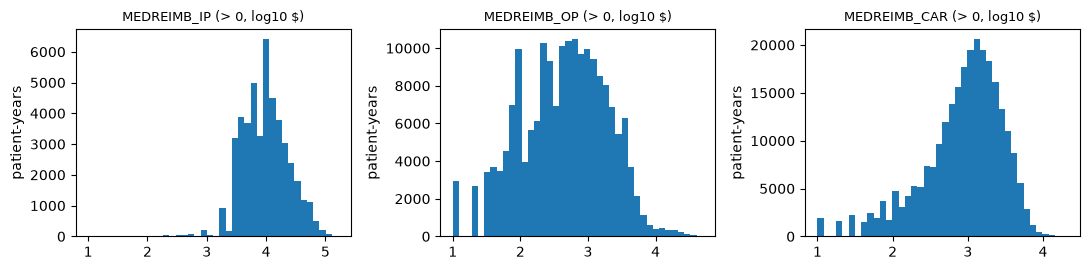

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
for a, c in zip(ax, ["MEDREIMB_IP", "MEDREIMB_OP", "MEDREIMB_CAR"]):
    a.hist(np.log10(by.loc[by[c] > 0, c]), bins=40)
    a.set_title(f"{c} (> 0, log10 $)", fontsize=9)
    a.set_ylabel("patient-years")
plt.tight_layout()
plt.show()
del _neg, _amt_rep

**Decision: keep amounts as they are.** No amount is missing. Only `MEDREIMB_IP` (28 rows) and `MEDREIMB_OP`
(197 rows) go negative, and always by small amounts (a few hundred dollars, at most -$3,000), which is what an
end-of-year adjustment/refund looks like in claims data. They are only ~0.07% of rows, so we do not clip or
drop them. The distributions are very right-skewed (most patient-years are $0; a few exceed $100,000 for
inpatient), but large inpatient bills are real for the sickest patients, so these are **not errors**. If an
amount is used in a model, use a log transform (for example `log1p` of the amount) rather than removing outliers.

**Leakage warning for modeling:** these are *annual totals*, which include the cost of the very admissions we are
trying to predict readmission for. Use them only as prior-year information, if at all.

### 1.6 Finalize `bene_year`

We put the columns in a sensible order and confirm the final key and dtypes.

In [10]:
bene_year = by[["DESYNPUF_ID", "YEAR", "BENE_BIRTH_DT", "BENE_DEATH_DT", "SEX", "RACE", "ESRD",
                "SP_STATE_CODE", "BENE_COUNTY_CD"] + _COVERAGE + ["ZERO_COVERAGE"] + _CHRONIC
               + ["N_CHRONIC"] + _AMT].sort_values(["DESYNPUF_ID", "YEAR"]).reset_index(drop=True)
bene_year["YEAR"] = bene_year["YEAR"].astype("int16")
assert not bene_year.duplicated(["DESYNPUF_ID", "YEAR"]).any()
log_step("bene_year", "final table", len(_b), len(bene_year), "one row per (DESYNPUF_ID, YEAR); nothing dropped")
print(f"bene_year: {bene_year.shape[0]:,} rows x {bene_year.shape[1]} cols")
display(bene_year.dtypes.astype(str).value_counts().to_frame("n_columns"))
display(bene_year.head(3))
del by, _b

[bene_year] final table: 343,644 -> 343,644 rows (0 removed) — one row per (DESYNPUF_ID, YEAR); nothing dropped
bene_year: 343,644 rows x 35 cols


,n_columns
int8,18
float64,9
object,3
category,2
datetime64[ns],2
int16,1


,DESYNPUF_ID,YEAR,BENE_BIRTH_DT,BENE_DEATH_DT,SEX,RACE,ESRD,SP_STATE_CODE,BENE_COUNTY_CD,BENE_HI_CVRAGE_TOT_MONS,BENE_SMI_CVRAGE_TOT_MONS,BENE_HMO_CVRAGE_TOT_MONS,PLAN_CVRG_MOS_NUM,ZERO_COVERAGE,SP_ALZHDMTA,SP_CHF,SP_CHRNKIDN,SP_CNCR,SP_COPD,SP_DEPRESSN,SP_DIABETES,SP_ISCHMCHT,SP_OSTEOPRS,SP_RA_OA,SP_STRKETIA,N_CHRONIC,MEDREIMB_IP,BENRES_IP,PPPYMT_IP,MEDREIMB_OP,BENRES_OP,PPPYMT_OP,MEDREIMB_CAR,BENRES_CAR,PPPYMT_CAR
0,00013D2EFD8E45D1,2008,1923-05-01,NaT,M,White,0,26,950,12,12,12,12,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,50.0,10.0,0.0,0.0,0.0,0.0
1,00013D2EFD8E45D1,2009,1923-05-01,NaT,M,White,0,26,950,12,12,12,12,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,100.0,20.0,0.0
2,00013D2EFD8E45D1,2010,1923-05-01,NaT,M,White,0,26,950,12,12,12,12,0,0,1,0,0,0,0,0,0,1,0,0,2,4000.0,1100.0,0.0,0.0,0.0,0.0,90.0,30.0,0.0


### 1.7 Build `bene_static` (one row per patient)

Fields that describe the person rather than the year should be identical in every yearly file. We test that, count
how many patients disagree, and then choose a rule for each field. (Fields like ESRD and the chronic flags are
expected to change, so they stay in `bene_year`; we only add `ESRD_EVER`.)

In [11]:
_g = bene_year.groupby("DESYNPUF_ID", observed=True)
_fixed = ["BENE_BIRTH_DT", "SEX", "RACE", "SP_STATE_CODE", "BENE_COUNTY_CD", "BENE_DEATH_DT"]
_multi = _g[_fixed].nunique(dropna=True)          # number of distinct non-blank values per patient
print("Patients with MORE THAN ONE distinct non-blank value across years:")
display((_multi > 1).sum().to_frame("patients_disagreeing"))
print("Patients whose ESRD status changes across years:", int((_g["ESRD"].nunique() > 1).sum()),
      "| whose chronic-condition count changes:", int((_g["N_CHRONIC"].nunique() > 1).sum()))

Patients with MORE THAN ONE distinct non-blank value across years:


,patients_disagreeing
BENE_BIRTH_DT,0
SEX,0
RACE,0
SP_STATE_CODE,0
BENE_COUNTY_CD,0
BENE_DEATH_DT,0


Patients whose ESRD status changes across years: 20010 | whose chronic-condition count changes: 83521


**What the data shows and the rule we use.**
* Birth date, sex, race, state and county never disagree between years (0 patients), so any rule gives the
  same answer; we take the **latest year's value** (`last`), which would also be the most up to date if they did.
* Death date: it is blank in earlier years and filled in only in the death year (see 1.4), and each patient has
  at most one distinct non-blank date. So the rule is **the single non-blank death date** (we take `min` of the
  non-blank dates, which equals `max` here). Taking the *latest year's* value would also work today, but "earliest
  non-blank" is the safer choice, since a death date is final once it is recorded.
* ESRD and chronic conditions do change between years (the synthetic data re-draws them), so we do not collapse
  them. For ESRD we add `ESRD_EVER` (1 if flagged in any year).
* `FIRST_YEAR` / `LAST_YEAR` record the years each patient appears in the files.

In [12]:
bene_static = _g.agg(
    BIRTH_DT=("BENE_BIRTH_DT", "last"),
    DEATH_DT=("BENE_DEATH_DT", "min"),
    SEX=("SEX", "last"),
    RACE=("RACE", "last"),
    SP_STATE_CODE=("SP_STATE_CODE", "last"),
    BENE_COUNTY_CD=("BENE_COUNTY_CD", "last"),
    ESRD_EVER=("ESRD", "max"),
    FIRST_YEAR=("YEAR", "min"),
    LAST_YEAR=("YEAR", "max"),
).reset_index()
bene_static["DIED"] = bene_static["DEATH_DT"].notna().astype("int8")
bene_static["FIRST_YEAR"] = bene_static["FIRST_YEAR"].astype("int16")
bene_static["LAST_YEAR"] = bene_static["LAST_YEAR"].astype("int16")
bene_static["ESRD_EVER"] = bene_static["ESRD_EVER"].astype("int8")

assert bene_static["DESYNPUF_ID"].is_unique
assert (bene_static.loc[bene_static["DIED"] == 1, "DEATH_DT"].dt.year == bene_static.loc[bene_static["DIED"] == 1, "LAST_YEAR"]).all()
log_step("bene_static", "collapse bene_year to one row per patient", len(bene_year), len(bene_static),
         "rows merged by patient, not dropped; birth/sex/race/state/county identical across years")

print(f"bene_static: {bene_static.shape[0]:,} rows x {bene_static.shape[1]} cols")
print(f"Patients who died in the window: {bene_static['DIED'].sum():,} ({bene_static['DIED'].mean():.1%});",
      "last file year of those = death year for all of them.")
print("Patients by (FIRST_YEAR, LAST_YEAR):", bene_static.groupby(["FIRST_YEAR", "LAST_YEAR"]).size().to_dict())
display(bene_static.head())
display(missing_report(bene_static, top=10))

[bene_static] collapse bene_year to one row per patient: 343,644 -> 116,352 rows (227,292 removed) — rows merged by patient, not dropped; birth/sex/race/state/county identical across years


bene_static: 116,352 rows x 11 cols
Patients who died in the window: 5,461 (4.7%); last file year of those = death year for all of them.
Patients by (FIRST_YEAR, LAST_YEAR): {(2008, 2008): 1814, (2008, 2009): 1784, (2008, 2010): 112754}


,DESYNPUF_ID,BIRTH_DT,DEATH_DT,SEX,RACE,SP_STATE_CODE,BENE_COUNTY_CD,ESRD_EVER,FIRST_YEAR,LAST_YEAR,DIED
0,00013D2EFD8E45D1,1923-05-01,NaT,M,White,26,950,0,2008,2010,0
1,00016F745862898F,1943-01-01,NaT,M,White,39,230,1,2008,2010,0
2,0001FDD721E223DC,1936-09-01,NaT,F,White,39,280,0,2008,2010,0
3,00021CA6FF03E670,1941-06-01,NaT,M,Hispanic,06,290,0,2008,2010,0
4,00024B3D2352D2D0,1936-08-01,NaT,M,White,52,590,0,2008,2010,0


,pct_missing
DEATH_DT,95.3
DESYNPUF_ID,0.0
BIRTH_DT,0.0
SEX,0.0
RACE,0.0
SP_STATE_CODE,0.0
BENE_COUNTY_CD,0.0
ESRD_EVER,0.0
FIRST_YEAR,0.0
LAST_YEAR,0.0


**Section summary**

* **`bene_year`** (one row per patient per year) and **`bene_static`** (one row per patient) are built from the three
  yearly beneficiary files. **No rows were dropped** from the beneficiary data; see `cleaning_log` for the counts.
* Types: dates are real dates; `SEX` (M/F) and `RACE` (White/Black/Other/Hispanic) are categoricals; `ESRD` and the
  11 chronic flags are 0/1 integers (CMS's 1/2 coding was reversed to "1 = has condition"); coverage months are
  integers in 0-12; state/county stay zero-padded strings. Renamed only `BENE_SEX_IDENT_CD` -> `SEX`,
  `BENE_RACE_CD` -> `RACE`, `BENE_ESRD_IND` -> `ESRD`. Added `N_CHRONIC`, `ZERO_COVERAGE`.
* The key (`DESYNPUF_ID`, `YEAR`) has no duplicates, there are no invalid codes, and no impossible dates (death
  before birth, outside the window, or after a patient's last row).
* **Zero-coverage patient-years are flagged, not dropped**, because they still own some admissions that would
  disappear in the claims join.
* **Negative amounts and large outliers are kept** (small refund-like negatives; big inpatient totals are real).
  Use log-scale if modeling with them, and treat annual totals as leakage-prone for same-year admissions.
* **Static fields never disagree across years**, so the reconciliation rule (latest value; the single non-blank death
  date) is safe. Death is recorded only in the death year and the patient disappears afterwards. All death and
  birth dates fall on the 1st of a month.
* ESRD status and chronic flags change between years for many patients (synthetic noise), so they are kept
  per year; `ESRD_EVER` summarizes ESRD.

## 2. Inpatient claims cleaning

The inpatient file has one row per *claim segment*: a hospital stay is normally one claim, but a few claims are split
into two rows. This section turns `raw_ip` into **`ip_clean` — exactly one row per inpatient claim (`CLM_ID`)** with
real dates, numeric amounts, intact string codes, and a trustworthy admission date, discharge date and length of stay.
Section 4 will use these dates to group claims into hospital stays and to decide whether a patient came back within
30 days, so date quality matters more here than anything else.

### 2.1 Missingness profile
First question for any table: which columns are empty? Columns that are 100% empty carry no information and only slow
everything down, so they can safely go. Columns that are *partly* empty need a closer look before we decide anything.

In [13]:
ip = raw_ip.copy()
ip_miss = missing_report(ip)

hcpcs_cols = [c for c in ip.columns if c.startswith("HCPCS_CD_")]
all_empty = ip_miss.index[ip_miss["pct_missing"] == 100].tolist()
print(f"Columns that are 100% empty: {len(all_empty)}  (of which HCPCS_CD_*: {len(set(all_empty) & set(hcpcs_cols))} "
      f"out of {len(hcpcs_cols)} HCPCS columns)")
print("Non-empty values across all HCPCS columns:", int(ip[hcpcs_cols].notna().sum().sum()))
print("\nMost-missing columns that still contain data:")
display(ip_miss[ip_miss["pct_missing"] < 100].head(12))

Columns that are 100% empty: 45  (of which HCPCS_CD_*: 45 out of 45 HCPCS columns)
Non-empty values across all HCPCS columns: 0

Most-missing columns that still contain data:


,pct_missing
ICD9_PRCDR_CD_6,93.1
ICD9_DGNS_CD_10,91.8
ICD9_PRCDR_CD_5,90.3
OT_PHYSN_NPI,88.5
ICD9_PRCDR_CD_4,86.0
ICD9_PRCDR_CD_3,78.3
ICD9_PRCDR_CD_2,66.0
ICD9_PRCDR_CD_1,42.7
OP_PHYSN_NPI,41.5
ICD9_DGNS_CD_9,32.6


All 45 `HCPCS_CD_*` columns have zero non-empty values (HCPCS procedure codes are only used on outpatient claims), so
we drop them. The other missing values are *structurally* expected: a claim lists as many diagnoses/procedures as it
has, so `ICD9_DGNS_CD_10` or `ICD9_PRCDR_CD_6` are mostly blank, and `OT_PHYSN_NPI` (other physician) is blank on most
claims. Those blanks are not errors, so we do **not** impute them. The tiny ~0.1% gaps in `CLM_FROM_DT`, `CLM_THRU_DT`
and `CLM_UTLZTN_DAY_CNT` are suspiciously close to the number of segment-2 rows, which we check next.

In [14]:
n0 = ip.shape[1]
ip = ip.drop(columns=all_empty)
print(f"Dropped {len(all_empty)} empty columns: {n0} -> {ip.shape[1]} columns")

Dropped 45 empty columns: 81 -> 36 columns

### 2.2 Duplicates and the `SEGMENT` column
Two checks: (a) are there exact duplicate rows? (b) does any `CLM_ID` appear more than once? The data dictionary says
`SEGMENT` 2 is a continuation of the same claim; we need to see what a continuation row actually contains before
merging it, because a naive "keep the first row" or "sum everything" could corrupt dates or costs.

In [15]:
print("Exact duplicate rows:            ", ip.duplicated().sum())
print("Rows with a repeated CLM_ID:     ", ip.CLM_ID.duplicated().sum())
print("Repeated (CLM_ID, SEGMENT) pairs:", ip.duplicated(["CLM_ID", "SEGMENT"]).sum())
print("Missing DESYNPUF_ID / CLM_ID:    ", ip.DESYNPUF_ID.isna().sum(), "/", ip.CLM_ID.isna().sum())
print("\nSEGMENT counts:")
print(ip.SEGMENT.value_counts().to_string())

seg2_ids = ip.loc[ip.SEGMENT == "2", "CLM_ID"]
print("\nSegments present for claims that have a segment 2:",
      ip[ip.CLM_ID.isin(seg2_ids)].groupby("CLM_ID").SEGMENT.agg(",".join).value_counts().to_dict())

s2 = ip[ip.SEGMENT == "2"]
print("\nColumns that are populated on segment-2 rows:")
print(s2.notna().sum()[lambda x: x > 0].to_dict())

Exact duplicate rows:             0
Rows with a repeated CLM_ID:      68
Repeated (CLM_ID, SEGMENT) pairs: 0
Missing DESYNPUF_ID / CLM_ID:     0 / 0

SEGMENT counts:
SEGMENT
1    66705
2       68

Segments present for claims that have a segment 2: {'2,1': 68}

Columns that are populated on segment-2 rows:
{'DESYNPUF_ID': 68, 'CLM_ID': 68, 'SEGMENT': 68, 'PRVDR_NUM': 68, 'CLM_PMT_AMT': 68, 'NCH_PRMRY_PYR_CLM_PD_AMT': 68, 'CLM_ADMSN_DT': 68, 'CLM_PASS_THRU_PER_DIEM_AMT': 68, 'NCH_BENE_IP_DDCTBL_AMT': 63, 'NCH_BENE_PTA_COINSRNC_LBLTY_AM': 68, 'NCH_BENE_BLOOD_DDCTBL_LBLTY_AM': 68, 'NCH_BENE_DSCHRG_DT': 68, 'CLM_DRG_CD': 68}


There are no exact duplicates and no missing patient or claim IDs. The only repeated `CLM_ID`s are the segment-2
rows, and every one of them has a matching segment-1 row. A segment-2 row carries **no** diagnoses, procedures,
physicians, `CLM_FROM_DT`/`CLM_THRU_DT` or utilization days — only payment amounts, an admission date, a discharge date,
a provider and a placeholder DRG. Let's compare it side by side with its segment-1 partner.

In [16]:
pair = ip[ip.SEGMENT == "1"].merge(s2, on="CLM_ID", suffixes=("_1", "_2"))
for c in ["DESYNPUF_ID", "PRVDR_NUM", "CLM_ADMSN_DT", "NCH_BENE_DSCHRG_DT"]:
    print(f"{c:<22} same in both segments: {(pair[c + '_1'] == pair[c + '_2']).mean():.0%}")
print("DRG on segment-2 rows:", s2.CLM_DRG_CD.value_counts().to_dict())

adm1, adm2, dis = to_date(pair.CLM_ADMSN_DT_1), to_date(pair.CLM_ADMSN_DT_2), to_date(pair.NCH_BENE_DSCHRG_DT_1)
print("\nSegment-2 admission date is earlier than segment-1 admission date in",
      f"{(adm2 < adm1).sum()} of {len(pair)} pairs; median gap {(adm1 - adm2).dt.days.median():.0f} days")
print("Segment-2 'stay length' (discharge - its admission), value counts:", (dis - adm2).dt.days.value_counts().to_dict())
util1 = pd.to_numeric(pair.CLM_UTLZTN_DAY_CNT_1)
print("Segment-1 utilization days equal segment-1 (discharge - admission) in",
      f"{(util1 == (dis - adm1).dt.days).mean():.0%} of pairs")
display(pair[["CLM_ID", "CLM_ADMSN_DT_1", "CLM_ADMSN_DT_2", "NCH_BENE_DSCHRG_DT_1", "NCH_BENE_DSCHRG_DT_2",
              "CLM_PMT_AMT_1", "CLM_PMT_AMT_2"]].head())
del pair, adm1, adm2, dis, util1

DESYNPUF_ID            same in both segments: 100%
PRVDR_NUM              same in both segments: 29%
CLM_ADMSN_DT           same in both segments: 10%
NCH_BENE_DSCHRG_DT     same in both segments: 100%
DRG on segment-2 rows: {'000': 35, 'OTH': 33}

Segment-2 admission date is earlier than segment-1 admission date in 61 of 68 pairs; median gap 26 days
Segment-2 'stay length' (discharge - its admission), value counts: {35: 68}
Segment-1 utilization days equal segment-1 (discharge - admission) in 85% of pairs


,CLM_ID,CLM_ADMSN_DT_1,CLM_ADMSN_DT_2,NCH_BENE_DSCHRG_DT_1,NCH_BENE_DSCHRG_DT_2,CLM_PMT_AMT_1,CLM_PMT_AMT_2
0,196901176966106,20080707,20080610,20080715,20080715,8000.00,11000.00
1,196531176970382,20090124,20090124,20090228,20090228,8000.00,8000.00
2,196821176998887,20090821,20090812,20090916,20090916,16000.00,42000.00
3,196101177023665,20081211,20081118,20081223,20081223,0.00,12000.00
4,196231176993156,20080616,20080528,20080702,20080702,24000.00,27000.00


**What this tells us.** Segment 2 belongs to the same patient and has the *same discharge date* and its own payment
(often a different `PRVDR_NUM`; its DRG is the placeholder `000`/`OTH`). Its admission date is usually *earlier* than
segment 1's, but the implied stay is **exactly 35 days in every pair** — it is just "discharge minus 35 days", a cap
or artifact of the synthetic data rather than an independent admission. Segment 1's own admission date, in contrast,
agrees with the claim's utilization-day count in most pairs. So we trust **segment 1's admission date** and use
segment 2 only for its money.

**Collapse rule — one row per `CLM_ID`:**
* **Codes, providers, diagnoses, procedures, DRG, `CLM_FROM_DT`/`CLM_THRU_DT`, utilization days** → taken from
  segment 1 (segment 2 has none, or only a placeholder).
* **Admission and discharge dates** → from segment 1 (discharge is identical in both segments; segment 2's admission
  is the 35-day artifact described above).
* **Money paid** (`CLM_PMT_AMT`, `NCH_PRMRY_PYR_CLM_PD_AMT`, coinsurance, blood deductible) → **summed**, since each
  segment bills a different piece of the stay.
* **`CLM_PASS_THRU_PER_DIEM_AMT`** is a *daily rate*, so summing is meaningless → we take the **max**.
  **`NCH_BENE_IP_DDCTBL_AMT`** is the patient's yearly deductible, repeated on every row → we take the **first** value
  (summing would double-count it).
* A new column `N_SEGMENTS` (1 or 2) records which claims were merged.

In [17]:
ip_before = len(ip)
ip["SEGMENT"] = ip["SEGMENT"].astype(int)
ip = ip.sort_values(["CLM_ID", "SEGMENT"], kind="stable")

money_sum = ["CLM_PMT_AMT", "NCH_PRMRY_PYR_CLM_PD_AMT", "NCH_BENE_PTA_COINSRNC_LBLTY_AM", "NCH_BENE_BLOOD_DDCTBL_LBLTY_AM"]
money_max = ["CLM_PASS_THRU_PER_DIEM_AMT"]
for c in money_sum + money_max + ["NCH_BENE_IP_DDCTBL_AMT", "CLM_UTLZTN_DAY_CNT"]:
    ip[c] = pd.to_numeric(ip[c], errors="coerce")        # amounts become numbers here (profiled in 2.4)

agg = {c: "first" for c in ip.columns if c != "CLM_ID"}   # 'first' = first non-missing value, i.e. segment 1
agg.update({c: "sum" for c in money_sum})
agg.update({c: "max" for c in money_max})
agg["SEGMENT"] = "size"
ip = ip.groupby("CLM_ID", sort=False).agg(agg).reset_index().rename(columns={"SEGMENT": "N_SEGMENTS"})

print("Rows:", ip_before, "->", len(ip), "| claims that were merged:", int((ip.N_SEGMENTS == 2).sum()))
print("CLM_ID unique:", ip.CLM_ID.is_unique)
log_step("inpatient", "collapse SEGMENT 1+2 into one row per CLM_ID", ip_before, len(ip),
         "dates/codes from segment 1, payments summed")

Rows: 66773 -> 66705 | claims that were merged: 68
CLM_ID unique: True
[inpatient] collapse SEGMENT 1+2 into one row per CLM_ID: 66,773 -> 66,705 rows (68 removed) — dates/codes from segment 1, payments summed


### 2.3 Dates, admission/discharge and length of stay
We convert the four date columns to real datetimes and check: blanks/invalid values, how
`CLM_ADMSN_DT`/`NCH_BENE_DSCHRG_DT` relate to the claim period `CLM_FROM_DT`/`CLM_THRU_DT`, and whether anything lies
outside the 2008–2010 study window. This is critical for readmission: the *gap between one discharge and the next
admission* is the target.

In [18]:
date_cols = ["CLM_FROM_DT", "CLM_THRU_DT", "CLM_ADMSN_DT", "NCH_BENE_DSCHRG_DT"]
for c in date_cols:
    parsed = to_date(ip[c])
    print(f"{c:<20} blank: {ip[c].isna().sum():>3}   present-but-invalid: {(ip[c].notna() & parsed.isna()).sum():>3}   "
          f"range: {parsed.min().date()} .. {parsed.max().date()}")
    ip[c] = parsed

print("\nAdmission == claim start (FROM):", f"{(ip.CLM_ADMSN_DT == ip.CLM_FROM_DT).mean():.2%}")
print("Discharge == claim end (THRU):  ", f"{(ip.NCH_BENE_DSCHRG_DT == ip.CLM_THRU_DT).mean():.2%}")
off = ip[ip.CLM_ADMSN_DT != ip.CLM_FROM_DT]
print("Admission differs from FROM in", len(off), "claims; admission is always earlier than FROM there:",
      bool((off.CLM_ADMSN_DT < off.CLM_FROM_DT).all()))

CLM_FROM_DT          blank:   0   present-but-invalid:   0   range: 2007-11-27 .. 2010-12-30
CLM_THRU_DT          blank:   0   present-but-invalid:   0   range: 2008-01-01 .. 2010-12-31
CLM_ADMSN_DT         blank:   0   present-but-invalid:   0   range: 2007-11-27 .. 2010-12-30
NCH_BENE_DSCHRG_DT   blank:   0   present-but-invalid:   0   range: 2008-01-01 .. 2010-12-31

Admission == claim start (FROM): 99.92%
Discharge == claim end (THRU):   100.00%
Admission differs from FROM in 53 claims; admission is always earlier than FROM there: True


No date is blank or malformed, and `NCH_BENE_DSCHRG_DT` equals `CLM_THRU_DT` on every claim, so the discharge date is
fully reliable. Admission equals `CLM_FROM_DT` on almost every claim; it is earlier only where the claim period started
after the patient was admitted. We still build the final `ADMSN_DT`/`DSCHRG_DT` with the **documented fallbacks**
(admission ← `CLM_ADMSN_DT`, then `CLM_FROM_DT`; discharge ← `NCH_BENE_DSCHRG_DT`, then `CLM_THRU_DT`) so
the code stays safe if a future extract has blanks, and then check consistency, window and length of stay.

In [19]:
ip["ADMSN_DT"] = ip["CLM_ADMSN_DT"].fillna(ip["CLM_FROM_DT"])
ip["DSCHRG_DT"] = ip["NCH_BENE_DSCHRG_DT"].fillna(ip["CLM_THRU_DT"])
print("Admission filled from CLM_FROM_DT:", int((ip.CLM_ADMSN_DT.isna() & ip.CLM_FROM_DT.notna()).sum()),
      "| discharge filled from CLM_THRU_DT:", int((ip.NCH_BENE_DSCHRG_DT.isna() & ip.CLM_THRU_DT.notna()).sum()))

ip["LOS_DAYS"] = (ip["DSCHRG_DT"] - ip["ADMSN_DT"]).dt.days
print("\nLOS_DAYS summary:")
print(ip.LOS_DAYS.describe().round(2).to_string())
print("Same-day stays (LOS = 0):", int((ip.LOS_DAYS == 0).sum()))
print("Largest LOS values (days: claims):", ip.LOS_DAYS.value_counts().sort_index().tail(4).to_dict())

Admission filled from CLM_FROM_DT: 0 | discharge filled from CLM_THRU_DT: 0

LOS_DAYS summary:
count    66705.00
mean         5.69
std          5.66
min          0.00
25%          2.00
50%          4.00
75%          7.00
max         35.00
Same-day stays (LOS = 0): 959
Largest LOS values (days: claims): {32: 61, 33: 65, 34: 38, 35: 567}


Length of stay is `DSCHRG_DT - ADMSN_DT` in days; a same-day admit/discharge is 0. Now the validity rules. A claim
cannot be used to build a stay if it has **no usable dates**, if the **discharge is before the admission**, or if it
lies **outside 2008–2010**. For admissions that began shortly before 1 Jan 2008 but were discharged inside the study
window we only *flag* them (`ADMSN_BEFORE_STUDY`): the stay is real and the discharge date is in range, so
dropping them would silently remove genuine discharges.

In [20]:
no_dates = ip.ADMSN_DT.isna() | ip.DSCHRG_DT.isna()
neg_los = ip.LOS_DAYS < 0
out_window = (ip.DSCHRG_DT < STUDY_START) | (ip.DSCHRG_DT > STUDY_END) | (ip.ADMSN_DT > STUDY_END)
print(f"No usable admission/discharge date: {no_dates.sum()} | discharge before admission: {neg_los.sum()} | "
      f"outside 2008-2010 (discharge before/after window or admission after): {out_window.sum()}")
print("Admissions before 2008-01-01 (flagged, kept):", int((ip.ADMSN_DT < STUDY_START).sum()),
      "| earliest admission:", ip.ADMSN_DT.min().date())

for mask, label in [(no_dates, "drop claims with no usable admission/discharge dates"),
                    (neg_los & ~no_dates, "drop claims with discharge before admission"),
                    (out_window & ~no_dates & ~neg_los, "drop claims outside the 2008-2010 window")]:
    before = len(ip)
    ip = ip[~mask.reindex(ip.index, fill_value=False)]
    log_step("inpatient", label, before, len(ip))

ip["ADMSN_BEFORE_STUDY"] = ip["ADMSN_DT"] < STUDY_START
ip["LOS_AT_CAP"] = ip["LOS_DAYS"] >= 35      # admission date truncated, see utilization discussion after this cell
ip["LOS_DAYS"] = ip["LOS_DAYS"].astype(int)
ip = ip.drop(columns=["CLM_ADMSN_DT", "NCH_BENE_DSCHRG_DT"])   # replaced by ADMSN_DT / DSCHRG_DT
ip = ip.reset_index(drop=True)

No usable admission/discharge date: 0 | discharge before admission: 0 | outside 2008-2010 (discharge before/after window or admission after): 0
Admissions before 2008-01-01 (flagged, kept): 224 | earliest admission: 2007-11-27


[inpatient] drop claims with no usable admission/discharge dates: 66,705 -> 66,705 rows (0 removed)
[inpatient] drop claims with discharge before admission: 66,705 -> 66,705 rows (0 removed)
[inpatient] drop claims outside the 2008-2010 window: 66,705 -> 66,705 rows (0 removed)


Nothing needed to be dropped: every claim has valid dates, no discharge precedes an admission, and all discharges fall
in 2008–2010. The `log_step` lines above record the zero-row steps so the audit trail is complete. The claims admitted
in late 2007 are kept and flagged.

**Utilization days vs. length of stay.** `CLM_UTLZTN_DAY_CNT` is the number of covered days billed. If it matches
`LOS_DAYS`, our dates agree with the claim's own count; where it doesn't, the dates are the more reliable signal for
readmission timing (readmission depends on calendar dates, not billed days).

In [21]:
diff = ip.CLM_UTLZTN_DAY_CNT - ip.LOS_DAYS
print("Utilization days missing:", int(ip.CLM_UTLZTN_DAY_CNT.isna().sum()))
print("Utilization == LOS:", f"{(diff == 0).mean():.1%}", "| within +/-1 day:", f"{(diff.abs() <= 1).mean():.1%}")
print("Most common (utilization - LOS):", diff.value_counts().head(5).to_dict())
big = ip[diff.abs() > 1]
print(f"\n{len(big)} claims differ by more than 1 day; median utilization {big.CLM_UTLZTN_DAY_CNT.median():.0f} "
      f"vs median LOS {big.LOS_DAYS.median():.0f}; utilization is 0 on {int((big.CLM_UTLZTN_DAY_CNT == 0).sum())}")

at_cap = ip.LOS_DAYS == ip.LOS_DAYS.max()
print(f"\nClaims at the maximum LOS ({ip.LOS_DAYS.max()} days): {int(at_cap.sum())}; of these, utilization > LOS on "
      f"{int((ip.CLM_UTLZTN_DAY_CNT[at_cap] > ip.LOS_DAYS.max()).sum())}, utilization up to {int(ip.CLM_UTLZTN_DAY_CNT.max())}")
print("Claims with utilization > 35 days whose LOS is below 35:",
      int(((ip.CLM_UTLZTN_DAY_CNT > 35) & (ip.LOS_DAYS < 35)).sum()))

Utilization days missing: 0
Utilization == LOS: 94.6% | within +/-1 day: 96.5%
Most common (utilization - LOS): {0.0: 63109, 1.0: 785, -2.0: 453, -1.0: 448, -3.0: 373}

2363 claims differ by more than 1 day; median utilization 0 vs median LOS 6; utilization is 0 on 1643

Claims at the maximum LOS (35 days): 567; of these, utilization > LOS on 421, utilization up to 136
Claims with utilization > 35 days whose LOS is below 35: 0


Utilization days equal the date-based length of stay on most claims (~95%). Of the rest, many have a utilization of 0
(or a tiny count) on a long stay — typical of days not billable to Medicare Part A.

**Surprise: `LOS_DAYS` is capped at 35.** No admission is ever more than 35 days before its discharge, yet a few hundred
claims report more than 35 utilization days (up to 136), and none of those has a shorter LOS. So for very long stays the
*admission date is truncated* to "discharge minus 35 days" (the same artifact seen in segment 2). The **discharge date
is unaffected**, which is the date that drives the readmission label, so we keep these rows and add a flag
`LOS_AT_CAP` (LOS = 35) so models and analyses can treat their length of stay as "35 or more". We **keep
`CLM_UTLZTN_DAY_CNT` as given**, and nothing is dropped because the two disagree.

### 2.4 Payment amounts
Amount columns are already numeric (converted during the merge). Medicare costs are **heavy-tailed**, so a big payment
is not an error and we do not remove outliers just for being large. What we look for are impossible values (negative
amounts where a negative makes no sense) and what the zeros mean.

In [22]:
amt_cols = ["CLM_PMT_AMT", "NCH_PRMRY_PYR_CLM_PD_AMT", "CLM_PASS_THRU_PER_DIEM_AMT", "NCH_BENE_IP_DDCTBL_AMT",
            "NCH_BENE_PTA_COINSRNC_LBLTY_AM", "NCH_BENE_BLOOD_DDCTBL_LBLTY_AM"]
amt_prof = pd.DataFrame({
    "missing": ip[amt_cols].isna().sum(),
    "negative": (ip[amt_cols] < 0).sum(),
    "zero": (ip[amt_cols] == 0).sum(),
    "median": ip[amt_cols].median(),
    "p99": ip[amt_cols].quantile(0.99),
    "max": ip[amt_cols].max(),
}).round(0)
display(amt_prof)

neg = ip[ip.CLM_PMT_AMT < 0]
print(f"\nNegative CLM_PMT_AMT: {len(neg)} claims, values between {neg.CLM_PMT_AMT.min():.0f} and {neg.CLM_PMT_AMT.max():.0f}; "
      f"median |value| = {neg.CLM_PMT_AMT.abs().median():.0f} vs overall median payment {ip.CLM_PMT_AMT.median():.0f}")
print("Zero payments with a primary-payer amount > 0:",
      int(((ip.CLM_PMT_AMT == 0) & (ip.NCH_PRMRY_PYR_CLM_PD_AMT > 0)).sum()), "of", int((ip.CLM_PMT_AMT == 0).sum()))
print("Yearly deductible values seen:", sorted(ip.NCH_BENE_IP_DDCTBL_AMT.dropna().unique().tolist()),
      "| missing:", int(ip.NCH_BENE_IP_DDCTBL_AMT.isna().sum()))

,missing,negative,zero,median,p99,max
CLM_PMT_AMT,0,55,2155,7000.0,57000.0,114000.0
NCH_PRMRY_PYR_CLM_PD_AMT,0,0,65178,0.0,13000.0,68000.0
CLM_PASS_THRU_PER_DIEM_AMT,0,0,47740,0.0,400.0,500.0
NCH_BENE_IP_DDCTBL_AMT,2167,0,0,1068.0,1100.0,1100.0
NCH_BENE_PTA_COINSRNC_LBLTY_AM,0,0,65281,0.0,2000.0,34000.0
NCH_BENE_BLOOD_DDCTBL_LBLTY_AM,0,0,66529,0.0,0.0,2000.0



Negative CLM_PMT_AMT: 55 claims, values between -8000 and -20; median |value| = 200 vs overall median payment 7000
Zero payments with a primary-payer amount > 0: 53 of 2155
Yearly deductible values seen: [1024.0, 1068.0, 1100.0] | missing: 2167


* **Negative `CLM_PMT_AMT`** appears on only a small number of claims and the amounts are small (adjustments or
  reversals, not real hospital payments). They are plausible in real claims data, so we **keep them** and add a flag
  `PMT_NEGATIVE` instead of changing the value.
* **Zero payments** are fairly common (another insurer or the beneficiary paid, or no Medicare liability) and legitimate.
* **Large payments**: the maximum is not absurd and the distribution is simply right-skewed; we leave all values and
  suggest a log transform (`log1p`) later only if a model needs it.
* The yearly **deductible** takes just three values (one per year) and is blank on a few percent of claims; we leave
  the blanks as `NaN` because the value is not needed to build the label.
* The other amounts are mostly zero (primary payer, coinsurance, blood deductible), which is expected.

The plot below shows the skew in payments and the shape of the length of stay.

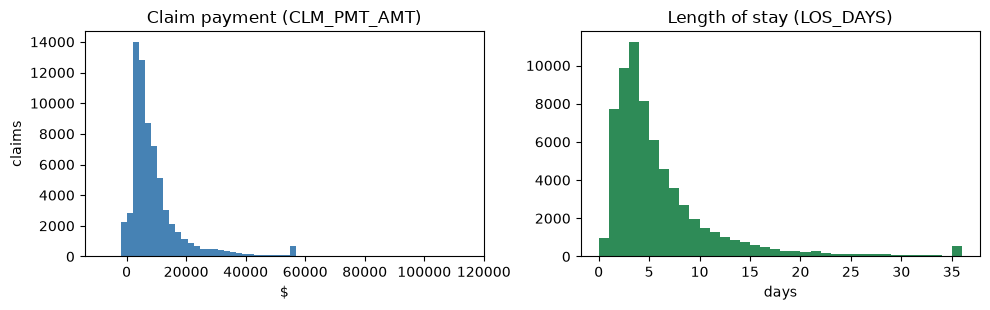

In [23]:
import matplotlib.pyplot as plt

ip["PMT_NEGATIVE"] = ip.CLM_PMT_AMT < 0
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(ip.CLM_PMT_AMT, bins=60, color="steelblue")
ax[0].set_title("Claim payment (CLM_PMT_AMT)"); ax[0].set_xlabel("$"); ax[0].set_ylabel("claims")
ax[1].hist(ip.LOS_DAYS, bins=range(0, 37), color="seagreen")
ax[1].set_title("Length of stay (LOS_DAYS)"); ax[1].set_xlabel("days")
plt.tight_layout(); plt.show()

Payments are right-skewed with a hard ceiling and length of stay is concentrated at 1–7 days with a long thin tail.
Both look like genuine heavy-tailed healthcare data, not data-entry errors.

### 2.5 Codes stay as strings
Provider numbers, NPIs, DRG and ICD-9 codes are identifiers, not quantities. Converting them to numbers would destroy
leading zeros (`0389` → `389`), `V`/`E` prefixes and the meaning of the code. We keep them as text, strip whitespace
and any float artifacts such as `.0`, and look for unexpected values.

In [24]:
def _ip_clean_code(s):
    s = s.astype("string").str.strip().str.replace(r"\.0+$", "", regex=True)
    return s.mask(s.isin(["", "nan", "NaN", "None"]))

npi_cols = ["AT_PHYSN_NPI", "OP_PHYSN_NPI", "OT_PHYSN_NPI"]
dx_cols = [f"ICD9_DGNS_CD_{i}" for i in range(1, 11)]
px_cols = [f"ICD9_PRCDR_CD_{i}" for i in range(1, 7)]
code_cols = ["PRVDR_NUM"] + npi_cols + ["CLM_DRG_CD", "ADMTNG_ICD9_DGNS_CD"] + dx_cols + px_cols

changed = 0
for c in code_cols:
    cleaned = _ip_clean_code(ip[c])
    changed += int((cleaned.fillna("") != ip[c].astype("string").fillna("")).sum())
    ip[c] = cleaned.astype(object)
print("Values changed by whitespace / '.0' cleanup:", changed)

npi_pat = r"\d{10}"
print("\nNPI format (should be exactly 10 digits):")
for c in npi_cols:
    v = ip[c].dropna()
    print(f"  {c}: {len(v):,} present, {v.str.fullmatch(npi_pat).mean():.1%} are 10 digits")
print("PRVDR_NUM lengths:", ip.PRVDR_NUM.str.len().value_counts().to_dict(), "| distinct providers:", ip.PRVDR_NUM.nunique())
print("DESYNPUF_ID missing:", int(ip.DESYNPUF_ID.isna().sum()), "| 16-char hex format:",
      f"{ip.DESYNPUF_ID.str.fullmatch(r'[0-9A-F]{16}').mean():.1%}")

Values changed by whitespace / '.0' cleanup: 0

NPI format (should be exactly 10 digits):
  AT_PHYSN_NPI: 66,100 present, 100.0% are 10 digits
  OP_PHYSN_NPI: 39,058 present, 100.0% are 10 digits
  OT_PHYSN_NPI: 7,683 present, 100.0% are 10 digits
PRVDR_NUM lengths: {6: 66705} | distinct providers: 2675
DESYNPUF_ID missing: 0 | 16-char hex format: 100.0%


NPIs are all 10-digit strings and provider numbers are all 6 characters, so no repair was needed, and every claim has
a patient ID. Now the clinical codes. ICD-9 diagnosis codes should be 3–5 characters of digits, or start with `V` or
`E`. DRG should be a 3-digit number. We also check the procedure columns, which should hold shorter 3–4 digit
procedure codes.

In [25]:
dx_vals = ip[["ADMTNG_ICD9_DGNS_CD"] + dx_cols].stack()
print("Diagnosis codes:", len(dx_vals), "| unexpected format:",
      int((~dx_vals.str.fullmatch(r"(\d{3,5}|V\d{2,4}|E\d{3,4})")).sum()),
      "| V-codes:", int(dx_vals.str.startswith("V").sum()), "| E-codes:", int(dx_vals.str.startswith("E").sum()))

print("\nDRG not 3 digits ->", ip.CLM_DRG_CD[~ip.CLM_DRG_CD.str.fullmatch(r"\d{3}")].value_counts().to_dict(),
      "| '000':", int((ip.CLM_DRG_CD == "000").sum()))

px_vals = ip[px_cols].stack()
valid_px = px_vals.str.fullmatch(r"\d{3,4}")
print("\nProcedure codes:", len(px_vals), "| look like real ICD-9 procedures (3-4 digits):", f"{valid_px.mean():.1%}")
print("Non-procedure-looking examples:", px_vals[~valid_px].value_counts().head(5).to_dict())
print("Share of such values by column:",
      {c: round(float((~ip[c].dropna().str.fullmatch(r"\d{3,4}")).mean()), 2) for c in px_cols})

Diagnosis codes: 603445 | unexpected format: 0 | V-codes: 47836 | E-codes: 8276

DRG not 3 digits -> {'OTH': 225} | '000': 200

Procedure codes: 95871 | look like real ICD-9 procedures (3-4 digits): 68.3%
Non-procedure-looking examples: {'25000': 1566, '41401': 1360, '42731': 1171, '53081': 1026, '51881': 556}
Share of such values by column: {'ICD9_PRCDR_CD_1': 0.0, 'ICD9_PRCDR_CD_2': 0.52, 'ICD9_PRCDR_CD_3': 0.53, 'ICD9_PRCDR_CD_4': 0.53, 'ICD9_PRCDR_CD_5': 0.53, 'ICD9_PRCDR_CD_6': 0.53}


Findings:
* **Diagnoses** all follow valid ICD-9 formats (including common `V5789` rehab and `E` external-cause codes), so they
  are kept as is.
* **DRG** is a 3-digit number except for `OTH` ("other", no DRG assigned) and `000` (placeholder). They are values
  that really occur in this file but carry no clinical information, so we add a flag `DRG_UNGROUPED` rather than
  guessing a replacement.
* **Procedure columns have a surprising quirk.** `ICD9_PRCDR_CD_1` always looks like a real procedure code, but
  from `_2` onward about half of the values are 5-character or `V`/`E` codes that are really **diagnosis codes**
  (e.g. `25000`, `V1254`). This looks like an artifact of how the synthetic data was generated. We do not "fix" or
  delete them (we can't know the true value), but `N_PRCDR_VALID` counts only genuine-looking procedure codes so
  later feature work can choose which to trust.

Next we count how many diagnosis and procedure codes each claim has — a simple proxy for how complex the stay was.

In [26]:
ip["N_DX"] = ip[dx_cols].notna().sum(axis=1)
ip["N_PRCDR"] = ip[px_cols].notna().sum(axis=1)
ip["N_PRCDR_VALID"] = sum(ip[c].str.fullmatch(r"\d{3,4}").eq(True).astype(int) for c in px_cols)
ip["DRG_UNGROUPED"] = ip.CLM_DRG_CD.isin(["000", "OTH"])

dx_present = ip[dx_cols].notna().to_numpy()
gaps = (dx_present[:, 1:] & ~dx_present[:, :-1]).any(axis=1).sum()
print("Claims with no diagnosis at all:", int((ip.N_DX == 0).sum()),
      "| diagnosis list with a gap (e.g. dx2 blank, dx3 filled):", int(gaps))
print("Claims with no attending physician (AT_PHYSN_NPI):", int(ip.AT_PHYSN_NPI.isna().sum()))
display(ip[["N_DX", "N_PRCDR", "N_PRCDR_VALID"]].describe().loc[["mean", "min", "50%", "max"]].round(2))
print("DRG_UNGROUPED claims:", int(ip.DRG_UNGROUPED.sum()))

Claims with no diagnosis at all: 0 | diagnosis list with a gap (e.g. dx2 blank, dx3 filled): 604
Claims with no attending physician (AT_PHYSN_NPI): 605


,N_DX,N_PRCDR,N_PRCDR_VALID
mean,8.05,1.44,0.98
min,1.00,0.00,0.00
50%,9.00,1.00,1.00
max,10.00,6.00,6.00


DRG_UNGROUPED claims: 425


A few claims have no diagnosis or no attending physician; they are kept because the dates (which build the label) are
complete, and downstream features can handle missing codes. The occasional gap in the diagnosis list is harmless since
we only count non-blank codes.

**Same patient, same dates, different `CLM_ID`.** One last sanity check for section 4: a few patients have two claims
with the identical admission and discharge date. We only report this here; section 4 decides how to merge stays.

In [27]:
k = ["DESYNPUF_ID", "ADMSN_DT", "DSCHRG_DT"]
dup_stay = ip.duplicated(k, keep=False)
print("Claims sharing patient + admission + discharge with another claim:", int(dup_stay.sum()),
      f"({dup_stay.mean():.2%} of claims)")

Claims sharing patient + admission + discharge with another claim: 24 (0.04% of claims)


### 2.6 Final column order and checks

In [28]:
id_cols = ["DESYNPUF_ID", "CLM_ID", "N_SEGMENTS"]
date_out = ["CLM_FROM_DT", "CLM_THRU_DT", "ADMSN_DT", "DSCHRG_DT", "LOS_DAYS", "LOS_AT_CAP", "ADMSN_BEFORE_STUDY"]
amt_out = ["CLM_PMT_AMT", "PMT_NEGATIVE", "NCH_PRMRY_PYR_CLM_PD_AMT", "CLM_PASS_THRU_PER_DIEM_AMT", "NCH_BENE_IP_DDCTBL_AMT",
           "NCH_BENE_PTA_COINSRNC_LBLTY_AM", "NCH_BENE_BLOOD_DDCTBL_LBLTY_AM", "CLM_UTLZTN_DAY_CNT"]
ip_clean = ip[id_cols + date_out + ["PRVDR_NUM"] + npi_cols + amt_out + ["CLM_DRG_CD", "DRG_UNGROUPED", "ADMTNG_ICD9_DGNS_CD"]
              + dx_cols + px_cols + ["N_DX", "N_PRCDR", "N_PRCDR_VALID"]].copy()
ip_clean["N_SEGMENTS"] = ip_clean["N_SEGMENTS"].astype(int)
ip_clean = ip_clean.sort_values(["DESYNPUF_ID", "ADMSN_DT", "CLM_ID"]).reset_index(drop=True)

assert ip_clean.CLM_ID.is_unique and ip_clean.DESYNPUF_ID.notna().all()
assert ip_clean[["ADMSN_DT", "DSCHRG_DT"]].notna().all().all() and (ip_clean.LOS_DAYS >= 0).all()
print("ip_clean:", ip_clean.shape, "| patients:", ip_clean.DESYNPUF_ID.nunique())
display(ip_clean[id_cols + date_out[:5] + ["CLM_PMT_AMT", "CLM_DRG_CD", "N_DX", "N_PRCDR"]].head())

del ip, ip_miss, s2, seg2_ids, dx_vals, px_vals, valid_px, dx_present

ip_clean: (66705, 44) | patients: 37780


,DESYNPUF_ID,CLM_ID,N_SEGMENTS,CLM_FROM_DT,CLM_THRU_DT,ADMSN_DT,DSCHRG_DT,LOS_DAYS,CLM_PMT_AMT,CLM_DRG_CD,N_DX,N_PRCDR
0,00013D2EFD8E45D1,196661176988405,1,2010-03-12,2010-03-13,2010-03-12,2010-03-13,1,4000.0,217,9,0
1,00016F745862898F,196201177000368,1,2009-04-12,2009-04-18,2009-04-12,2009-04-18,6,26000.0,201,9,0
2,00016F745862898F,196661177015632,1,2009-08-31,2009-09-02,2009-08-31,2009-09-02,2,5000.0,750,3,3
3,00016F745862898F,196091176981058,1,2009-09-17,2009-09-20,2009-09-17,2009-09-20,3,5000.0,883,6,0
4,00016F745862898F,196261176983265,1,2010-06-26,2010-07-01,2010-06-26,2010-07-01,5,16000.0,983,9,1


**Section summary**

* **Columns:** the 45 all-empty `HCPCS_CD_*` columns were dropped (they are only used on outpatient claims). Other
  blanks (extra diagnoses/procedures, other-physician NPI) are structural and were left as missing.
* **Duplicates / segments:** no exact duplicate rows. The 68 `SEGMENT` 2 rows were merged into their segment-1 claim:
  dates and all codes from segment 1 (segment 2's admission is just "discharge minus 35 days"), payments summed
  (per-diem rate = max, yearly deductible = first). Result: one row per `CLM_ID` (`N_SEGMENTS` marks merged claims).
* **Dates:** all four date columns parsed with no blank or invalid values; discharge equals `CLM_THRU_DT` on every claim.
  `ADMSN_DT` / `DSCHRG_DT` / `LOS_DAYS` created (with documented fallbacks that were not needed). No rows dropped for
  bad dates, negative stays or out-of-window discharges; admissions before 2008 are kept and flagged
  (`ADMSN_BEFORE_STUDY`).
* **Utilization days** match the date-based LOS on most claims; we keep both and rely on `LOS_DAYS`. `LOS_DAYS` is capped
  at 35 in this synthetic data (truncated admission dates on long stays), flagged by `LOS_AT_CAP`; discharge dates are
  unaffected.
* **Amounts:** numeric; negative payments (a few small adjustments) kept and flagged `PMT_NEGATIVE`; zeros legitimate;
  large values kept because costs are heavy-tailed.
* **Codes:** all kept as strings; no `.0` / whitespace artifacts; NPIs are 10 digits. `DRG_UNGROUPED` flags DRG `000`/`OTH`.
  Procedure columns `_2`–`_6` contain many diagnosis-like codes, so `N_PRCDR_VALID` counts only genuine-looking ones.
  `N_DX` and `N_PRCDR` count non-missing codes.
* **Output:** `ip_clean` (printed above), one row per inpatient claim, sorted by patient and admission date. Beneficiary
  cross-checks and stay/readmission logic are left to section 4. Possible duplicate stays (same patient and dates but
  different `CLM_ID`) are reported but not removed here.

## 3. Outpatient claims cleaning

Outpatient claims are doctor visits, ER visits, lab work and other hospital-outpatient services. We do **not** predict
anything from them directly; their job is to describe each patient's **recent health-care use before an admission**
(e.g. "how many outpatient visits in the 30 / 365 days before this admission?"). So the goal here is a **lean**
table with one row per claim: who, when, how much was paid, the main diagnosis and a few counts. The 76 raw columns
(mostly wide, mostly empty code lists) would cost gigabytes of memory in Colab for no modeling benefit.

### 3.1 First look and missingness
Before changing anything we look at how complete each column is. In claims data a "wide" list of codes
(`ICD9_DGNS_CD_1…10`, `HCPCS_CD_1…45`) is filled left-to-right, so the later columns are empty for most claims.

In [29]:
print(f"raw_op: {raw_op.shape[0]:,} rows x {raw_op.shape[1]} cols, "
      f"{raw_op.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory")

_op_miss = missing_report(raw_op)
_op_groups = {
    "ICD9_DGNS_CD_1..10 (diagnoses)": [c for c in raw_op.columns if c.startswith("ICD9_DGNS_CD_")],
    "ICD9_PRCDR_CD_1..6 (procedures)": [c for c in raw_op.columns if c.startswith("ICD9_PRCDR_CD_")],
    "HCPCS_CD_1..45 (service codes)": [c for c in raw_op.columns if c.startswith("HCPCS_CD_")],
    "physician NPIs": ["AT_PHYSN_NPI", "OP_PHYSN_NPI", "OT_PHYSN_NPI"],
    "ADMTNG_ICD9_DGNS_CD": ["ADMTNG_ICD9_DGNS_CD"],
    "dates (FROM / THRU)": ["CLM_FROM_DT", "CLM_THRU_DT"],
}
_rows = []
for _name, _cols in _op_groups.items():
    _m = _op_miss.loc[_cols, "pct_missing"]
    _rows.append({"column group": _name, "n_cols": len(_cols), "avg % missing": round(_m.mean(), 1),
                  "min % missing": _m.min(), "max % missing": _m.max()})
display(pd.DataFrame(_rows).set_index("column group"))
print("Columns with >0% missing, worst 10:")
display(missing_report(raw_op, top=10))

raw_op: 790,790 rows x 76 cols, 2,294 MB in memory


,n_cols,avg % missing,min % missing,max % missing
column group,,,,
ICD9_DGNS_CD_1..10 (diagnoses),10,73.8,0.7,99.8
ICD9_PRCDR_CD_1..6 (procedures),6,100.0,100.0,100.0
HCPCS_CD_1..45 (service codes),45,89.4,18.3,100.0
physician NPIs,3,50.9,2.2,83.0
ADMTNG_ICD9_DGNS_CD,1,75.4,75.4,75.4
dates (FROM / THRU),2,1.4,1.4,1.4


Columns with >0% missing, worst 10:


,pct_missing
ICD9_PRCDR_CD_5,100.0
ICD9_PRCDR_CD_6,100.0
ICD9_PRCDR_CD_4,100.0
ICD9_PRCDR_CD_3,100.0
ICD9_PRCDR_CD_2,100.0
HCPCS_CD_45,100.0
ICD9_PRCDR_CD_1,100.0
ICD9_DGNS_CD_10,99.8
HCPCS_CD_44,98.7
HCPCS_CD_43,98.6


**What this tells us**
* `ICD9_PRCDR_CD_1…6` are **(almost) 100 % empty** — outpatient claims essentially carry no ICD-9 procedure codes
  (procedures appear as HCPCS instead). Their counts will be ~0 for nearly every claim.
* The diagnosis and HCPCS lists thin out quickly: the average claim has only a few codes, so the later columns are
  almost always empty.
* `CLM_FROM_DT` / `CLM_THRU_DT` are missing for about 1.4 % of rows — we will see below that this is a **segment**
  effect, not random.

**Decision on wide code columns:** for this table we only need to know *how many* diagnoses / HCPCS codes a claim
has (a rough measure of visit complexity) and the **primary diagnosis** (`ICD9_DGNS_CD_1`). We therefore compute the
counts first and then drop the wide code columns, rather than keep ~65 sparse columns.

### 3.2 SEGMENT, duplicate claims and one row per claim
A claim that is too long for one record is split into **SEGMENT 1** and **SEGMENT 2** rows sharing the same `CLM_ID`.
If we left both rows in, a single visit would be counted twice in "number of visits" features. We check exact
duplicate rows, duplicate `CLM_ID`s, and what a segment-2 row actually contains.

In [30]:
print("SEGMENT counts:"); display(raw_op["SEGMENT"].value_counts())

_n_dup_rows = raw_op.duplicated().sum()
_n_dup_ids = raw_op["CLM_ID"].duplicated().sum()
print(f"Exact duplicate rows:          {_n_dup_rows:,}")
print(f"Rows with a repeated CLM_ID:   {_n_dup_ids:,}  (unique CLM_IDs: {raw_op['CLM_ID'].nunique():,})")

_s2 = raw_op[raw_op["SEGMENT"] == "2"]
print("\nSegment-2 rows: share of rows where each column is filled (only columns > 0 %):")
display((_s2.notna().mean().mul(100).round(1))[lambda s: s > 0])

_ids_with_s1 = set(raw_op.loc[raw_op["SEGMENT"] == "1", "CLM_ID"])
_orphans = ~_s2["CLM_ID"].isin(_ids_with_s1)
print(f"\nSegment-2 rows whose CLM_ID has a segment 1:   {(~_orphans).sum():,}")
print(f"Segment-2 'orphans' (no segment 1 exists):      {_orphans.sum():,}")
print(f"Segment-2 rows with a missing date:             {_s2['CLM_FROM_DT'].isna().sum():,} of {len(_s2):,}")
print("Same CLM_ID under more than one patient:",
      (raw_op.groupby("CLM_ID")["DESYNPUF_ID"].nunique() > 1).sum())
print("\nExample of a split claim:")
_ex = raw_op.loc[raw_op["CLM_ID"] == raw_op.loc[raw_op["SEGMENT"] == "2", "CLM_ID"].iloc[0]]
display(_ex[["CLM_ID", "SEGMENT", "CLM_FROM_DT", "CLM_THRU_DT", "PRVDR_NUM", "CLM_PMT_AMT", "ICD9_DGNS_CD_1"]])

SEGMENT counts:


SEGMENT
1    779537
2     11253
Name: count, dtype: int64

Exact duplicate rows:          0


Rows with a repeated CLM_ID:   10,975  (unique CLM_IDs: 779,815)

Segment-2 rows: share of rows where each column is filled (only columns > 0 %):


DESYNPUF_ID                       100.0
CLM_ID                            100.0
SEGMENT                           100.0
PRVDR_NUM                         100.0
CLM_PMT_AMT                       100.0
NCH_PRMRY_PYR_CLM_PD_AMT          100.0
NCH_BENE_BLOOD_DDCTBL_LBLTY_AM    100.0
ICD9_DGNS_CD_1                     50.3
NCH_BENE_PTB_DDCTBL_AMT           100.0
NCH_BENE_PTB_COINSRNC_AMT         100.0
HCPCS_CD_1                         77.0
dtype: float64


Segment-2 rows whose CLM_ID has a segment 1:   10,975
Segment-2 'orphans' (no segment 1 exists):      278
Segment-2 rows with a missing date:             11,253 of 11,253


Same CLM_ID under more than one patient: 0

Example of a split claim:


,CLM_ID,SEGMENT,CLM_FROM_DT,CLM_THRU_DT,PRVDR_NUM,CLM_PMT_AMT,ICD9_DGNS_CD_1
8,542052281361022,2,NaN,NaN,3902NU,50.00,NaN
19,542052281361022,1,20090425,20090515,3902NU,60.00,71856


**Findings**
* There are **no exact duplicate rows** — nothing to remove on that front.
* Every repeated `CLM_ID` is exactly a segment-1 + segment-2 pair for the same patient.
* Segment-2 rows have **no dates at all** (that is the entire 1.4 % date gap), and their only diagnosis is the placeholder
  text `OTHER`. They are a *continuation of the payment* (they have their own `CLM_PMT_AMT`), not a separate visit.
* A few hundred segment-2 rows have **no matching segment 1**. They cannot be placed in time (no date), so they are useless
  for "visits in the 30 days before admission" and are dropped.

**Collapse rule — one row per `CLM_ID`:**
1. Take identity, dates, provider and primary diagnosis from the **segment-1** row.
2. **Sum the five dollar amounts** over both segments (the claim's real total payment).
3. Count diagnoses / HCPCS codes over **both** segments; the placeholder `OTHER` does not count as a diagnosis.

We use `notna()` over *all* columns for counts rather than "the last filled column", because the lists have gaps
(checked next).

In [31]:
_dx_cols = [c for c in raw_op.columns if c.startswith("ICD9_DGNS_CD_")]
_pr_cols = [c for c in raw_op.columns if c.startswith("ICD9_PRCDR_CD_")]
_hc_cols = [c for c in raw_op.columns if c.startswith("HCPCS_CD_")]

_dx_filled = raw_op[_dx_cols].notna().to_numpy()
_hc_filled = raw_op[_hc_cols].notna().to_numpy()
_gap = lambda m: (m[:, 1:] & ~m[:, :-1]).any(axis=1).sum()
print(f"Rows where a later dx column is filled but an earlier one is empty:   {_gap(_dx_filled):,}")
print(f"Rows where a later HCPCS column is filled but an earlier one is empty: {_gap(_hc_filled):,}")
print(f"  e.g. HCPCS_CD_1 is empty for {raw_op['HCPCS_CD_1'].isna().sum():,} rows, yet many of those have HCPCS_CD_2…")
del _dx_filled, _hc_filled

Rows where a later dx column is filled but an earlier one is empty:   3,634
Rows where a later HCPCS column is filled but an earlier one is empty: 149,542
  e.g. HCPCS_CD_1 is empty for 144,530 rows, yet many of those have HCPCS_CD_2…


Gaps exist, so counting filled cells (`notna().sum(axis=1)`) is the correct way to get `N_DX`, `N_HCPCS` and `N_PRCDR`.

One more feature is cheap to extract **before** the HCPCS columns are dropped and is clinically meaningful for
readmission: whether the visit was an **emergency-room visit**. ER evaluation-and-management HCPCS codes are
99281–99285. Prior ER use is a well-known risk marker.

Now we build the collapsed table.

In [32]:
_amt_cols = ["CLM_PMT_AMT", "NCH_PRMRY_PYR_CLM_PD_AMT", "NCH_BENE_BLOOD_DDCTBL_LBLTY_AM",
             "NCH_BENE_PTB_DDCTBL_AMT", "NCH_BENE_PTB_COINSRNC_AMT"]
_n0 = len(raw_op)

# step 1: drop exact duplicates (none expected; kept so the notebook stays correct if the data changes)
_op_work = raw_op if _n_dup_rows == 0 else raw_op.drop_duplicates()
log_step("outpatient", "drop exact duplicate rows", _n0, len(_op_work), "none present in Sample 1")

# per-row quantities computed on the raw (segment-level) rows
_seg = pd.DataFrame({"CLM_ID": _op_work["CLM_ID"].to_numpy()})
_dx_ok = _op_work[_dx_cols].notna() & _op_work[_dx_cols].ne("OTHER")
_seg["N_DX"] = _dx_ok.sum(axis=1).to_numpy()
_seg["N_PRCDR"] = _op_work[_pr_cols].notna().sum(axis=1).to_numpy()
_seg["N_HCPCS"] = _op_work[_hc_cols].notna().sum(axis=1).to_numpy()
_seg["ER_VISIT"] = _op_work[_hc_cols].isin(["99281", "99282", "99283", "99284", "99285"]).any(axis=1).to_numpy()
for _c in _amt_cols:
    _seg[_c] = pd.to_numeric(_op_work[_c], errors="coerce").to_numpy()
del _dx_ok

# step 2: collapse segments -> one row per CLM_ID
_per_claim = _seg.groupby("CLM_ID", sort=False).agg(
    {**{c: "sum" for c in _amt_cols}, "N_DX": "sum", "N_PRCDR": "sum", "N_HCPCS": "sum", "ER_VISIT": "max"})
del _seg

_base = _op_work.loc[_op_work["SEGMENT"] == "1",
                     ["DESYNPUF_ID", "CLM_ID", "CLM_FROM_DT", "CLM_THRU_DT", "PRVDR_NUM"]].copy()
_dx_first = _op_work.loc[_base.index, _dx_cols].where(lambda d: d.ne("OTHER"))
_base["ICD9_DGNS_CD_1"] = _dx_first.bfill(axis=1).iloc[:, 0]   # first real dx (fills 14 blank primaries)
del _dx_first, _op_work
_base = _base.drop_duplicates("CLM_ID")

op_clean = _base.join(_per_claim, on="CLM_ID").reset_index(drop=True)
del _base, _per_claim
log_step("outpatient", "collapse segments to one row per CLM_ID", _n0, len(op_clean),
         "kept segment-1 identity/dates; summed amounts; orphan segment-2 rows dropped")
print("CLM_ID unique:", op_clean["CLM_ID"].is_unique)
display(op_clean.head())

[outpatient] drop exact duplicate rows: 790,790 -> 790,790 rows (0 removed) — none present in Sample 1


[outpatient] collapse segments to one row per CLM_ID: 790,790 -> 779,537 rows (11,253 removed) — kept segment-1 identity/dates; summed amounts; orphan segment-2 rows dropped
CLM_ID unique: True


,DESYNPUF_ID,CLM_ID,CLM_FROM_DT,CLM_THRU_DT,PRVDR_NUM,ICD9_DGNS_CD_1,CLM_PMT_AMT,NCH_PRMRY_PYR_CLM_PD_AMT,NCH_BENE_BLOOD_DDCTBL_LBLTY_AM,NCH_BENE_PTB_DDCTBL_AMT,NCH_BENE_PTB_COINSRNC_AMT,N_DX,N_PRCDR,N_HCPCS,ER_VISIT
0,00013D2EFD8E45D1,542192281063886,20080904,20080904,2600RA,V5841,50.0,0.0,0.0,0.0,10.0,1,0,2,False
1,00016F745862898F,542272281166593,20090602,20090602,3901GS,V5832,30.0,0.0,0.0,0.0,0.0,6,0,9,False
2,00016F745862898F,542282281644416,20090623,20090623,3939PG,9594,30.0,0.0,0.0,0.0,70.0,3,0,3,False
3,0001FDD721E223DC,542642281250669,20091011,20091011,3902NU,78943,30.0,0.0,0.0,0.0,50.0,3,0,1,False
4,00024B3D2352D2D0,542242281386963,20080712,20080712,5200TV,6009,30.0,0.0,0.0,0.0,40.0,1,0,2,False


### 3.3 Dates
The window analysis needs real dates. We convert `YYYYMMDD` text to datetime and check three things: missing/invalid
dates, `THRU` earlier than `FROM`, and dates outside the 2008–2010 study window.

In [33]:
op_clean["CLM_FROM_DT"] = to_date(op_clean["CLM_FROM_DT"])
op_clean["CLM_THRU_DT"] = to_date(op_clean["CLM_THRU_DT"])

_f, _t = op_clean["CLM_FROM_DT"], op_clean["CLM_THRU_DT"]
_dur = (_t - _f).dt.days
print(f"Missing / invalid FROM: {_f.isna().sum():,}   THRU: {_t.isna().sum():,}")
print(f"THRU before FROM:       {(_t < _f).sum():,}")
print(f"FROM range: {_f.min().date()} .. {_f.max().date()}     THRU range: {_t.min().date()} .. {_t.max().date()}")
print(f"FROM before {STUDY_START.date()}: {(_f < STUDY_START).sum():,}   "
      f"(of these, THRU inside window: {((_f < STUDY_START) & (_t >= STUDY_START)).sum():,})")
print(f"THRU after  {STUDY_END.date()}: {(_t > STUDY_END).sum():,}")
print("\nClaim duration in days (THRU - FROM):")
display(_dur.describe().round(2).to_frame().T)
print("Most common durations:", _dur.value_counts().head(5).to_dict())

Missing / invalid FROM: 0   THRU: 0
THRU before FROM:       0
FROM range: 2007-12-12 .. 2010-12-31     THRU range: 2008-01-01 .. 2010-12-31
FROM before 2008-01-01: 312   (of these, THRU inside window: 312)
THRU after  2010-12-31: 0

Claim duration in days (THRU - FROM):


,count,mean,std,min,25%,50%,75%,max
0,779537.0,1.39,4.65,0.0,0.0,0.0,0.0,20.0


Most common durations: {0: 685135, 20: 35765, 1: 17525, 2: 6300, 14: 4067}


**Reading the evidence**
* After the segment collapse every claim has a valid FROM and THRU, and none ends before it starts.
* A small number of claims start in **December 2007** but end in January 2008. They are genuine claims overlapping the
  start of the study window, so we **keep** them (dropping them would only lose a few weeks of real history). We
  will use `CLM_FROM_DT` as "the date of the visit".
* Most outpatient claims are single-day (duration 0). A spike at exactly 20 days is a quirk of the synthetic data; it does
  not matter for us since we only use the start date.

The code below enforces these rules (drop missing dates, drop inverted ranges, drop claims that lie entirely outside
the study window) and logs the result, so it stays correct if the data changes.

In [34]:
_n = len(op_clean)
op_clean = op_clean[op_clean["CLM_FROM_DT"].notna() & op_clean["CLM_THRU_DT"].notna()]
log_step("outpatient", "drop claims with missing/invalid dates", _n, len(op_clean))

_n = len(op_clean)
op_clean = op_clean[op_clean["CLM_THRU_DT"] >= op_clean["CLM_FROM_DT"]]
log_step("outpatient", "drop claims with THRU before FROM", _n, len(op_clean))

_n = len(op_clean)
op_clean = op_clean[(op_clean["CLM_THRU_DT"] >= STUDY_START) & (op_clean["CLM_FROM_DT"] <= STUDY_END)]
log_step("outpatient", "drop claims entirely outside 2008-2010", _n, len(op_clean),
         "claims straddling 2008-01-01 are kept")
op_clean = op_clean.reset_index(drop=True)

[outpatient] drop claims with missing/invalid dates: 779,537 -> 779,537 rows (0 removed)


[outpatient] drop claims with THRU before FROM: 779,537 -> 779,537 rows (0 removed)


[outpatient] drop claims entirely outside 2008-2010: 779,537 -> 779,537 rows (0 removed) — claims straddling 2008-01-01 are kept


### 3.4 Payment amounts
Dollar columns were read as text; we convert them to numbers (already done during the collapse) and look for negatives,
zeros and extreme values. Medicare payments are naturally very skewed, so large values are **not** errors by default.
`CLM_PMT_AMT` is the amount Medicare paid; the others are what other insurance, the deductible or the patient's
coinsurance covered. Because `CLM_PMT_AMT` is the headline utilization-cost feature, it deserves the closest look.

In [35]:
_rows = []
for _c in _amt_cols:
    _x = op_clean[_c]
    _rows.append({"column": _c, "n_missing": _x.isna().sum(), "n_negative": (_x < 0).sum(), "n_zero": (_x == 0).sum(),
                  "pct_zero": round((_x == 0).mean() * 100, 1), "median": _x.median(),
                  "p99": _x.quantile(0.99), "max": _x.max()})
display(pd.DataFrame(_rows).set_index("column"))

_neg = op_clean[op_clean["CLM_PMT_AMT"] < 0]
print(f"\nNegative CLM_PMT_AMT: {len(_neg):,} claims; values: {_neg['CLM_PMT_AMT'].min():.0f} .. {_neg['CLM_PMT_AMT'].max():.0f}")
print("Most common negative values:", _neg["CLM_PMT_AMT"].value_counts().head(4).to_dict())
print("Zero-payment claims:", f"{(op_clean['CLM_PMT_AMT'] == 0).sum():,}",
      "| of those, patient coinsurance > 0:",
      f"{((op_clean['CLM_PMT_AMT'] == 0) & (op_clean['NCH_BENE_PTB_COINSRNC_AMT'] > 0)).sum():,}")
print("Distinct CLM_PMT_AMT values:", op_clean["CLM_PMT_AMT"].nunique(),
      "| claims above 3,300 (only possible via summed segments):", f"{(op_clean['CLM_PMT_AMT'] > 3300).sum():,}")

,n_missing,n_negative,n_zero,pct_zero,median,p99,max
column,,,,,,,
CLM_PMT_AMT,0,2557,29706,3.8,80.0,3300.0,6600.0
NCH_PRMRY_PYR_CLM_PD_AMT,0,0,772575,99.1,0.0,0.0,14000.0
NCH_BENE_BLOOD_DDCTBL_LBLTY_AM,0,0,779504,100.0,0.0,0.0,800.0
NCH_BENE_PTB_DDCTBL_AMT,0,0,746742,95.8,0.0,100.0,400.0
NCH_BENE_PTB_COINSRNC_AMT,0,0,264142,33.9,20.0,1100.0,2200.0



Negative CLM_PMT_AMT: 2,557 claims; values: -100 .. -10
Most common negative values: {-10.0: 766, -20.0: 503, -30.0: 344, -60.0: 286}
Zero-payment claims: 29,706 | of those, patient coinsurance > 0: 19,700
Distinct CLM_PMT_AMT values: 346 | claims above 3,300 (only possible via summed segments): 4,866


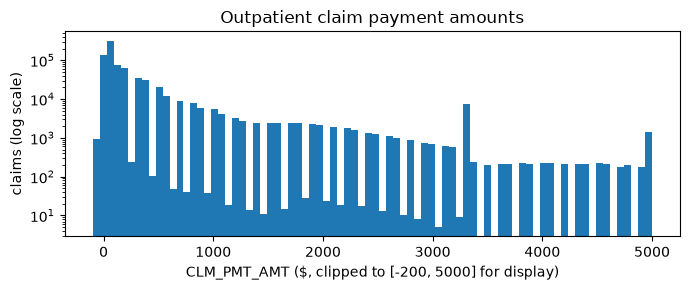

In [36]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(op_clean["CLM_PMT_AMT"].clip(-200, 5000), bins=80)
ax.set_yscale("log")
ax.set_xlabel("CLM_PMT_AMT ($, clipped to [-200, 5000] for display)")
ax.set_ylabel("claims (log scale)")
ax.set_title("Outpatient claim payment amounts")
plt.tight_layout()
plt.show()
plt.close(fig)

**Decisions on amounts**
* **Negative payments** are small adjustments/refunds (typically −$10 to −$100). They are real accounting entries in
  claims data, not typos, and a few thousand out of ~780k is negligible, so we **keep** them and add a flag
  `PMT_NEGATIVE` so they can be inspected or excluded in modeling.
* **Zero payments** are common and legitimate (e.g. the visit applied to the patient's deductible; many of them show
  patient coinsurance > 0). Still a visit — it counts as utilization — so we **keep** them.
* **Heavy tail:** a single record never exceeds $3,300 (many claims pile up at that cap, i.e. the synthetic generator
  capped it); a claim's total can reach about twice that because we summed two segments. There is no
  wild outlier to remove. We do not winsorize or drop anything; tree models are insensitive to this and, if needed, the
  modeling stage can log-transform sums over the look-back window.
* `NCH_BENE_BLOOD_DDCTBL_LBLTY_AM` is almost always 0 and `NCH_PRMRY_PYR_CLM_PD_AMT` mostly 0, so they are only weakly
  informative, but they are cheap to keep and no rows are changed.

In [37]:
op_clean["PMT_NEGATIVE"] = op_clean["CLM_PMT_AMT"] < 0

### 3.5 Codes stay as strings; final lean table
Identifiers and codes must stay **text**: `PRVDR_NUM` (provider number such as `3902NU`) and `ICD9_DGNS_CD_1` (ICD-9
such as `0389`, `V5789`, `E8xx`). Leading zeros would be lost and the V/E prefixes would break in a numeric type. We check
that no float artifacts (`'4019.0'`) crept in, mark the placeholder `OTHER` and missing values consistently as `NaN`, then shrink
dtypes (float32 amounts, small ints for counts, `category` for repeated strings) and compare memory.

In [38]:
for _c in ["DESYNPUF_ID", "CLM_ID", "PRVDR_NUM", "ICD9_DGNS_CD_1"]:
    _s = op_clean[_c].dropna()
    print(f"{_c:<15} len set: {sorted(_s.str.len().unique())}   ends with '.0': {_s.str.endswith('.0').sum()}   "
          f"has whitespace: {(_s != _s.str.strip()).sum()}   missing: {op_clean[_c].isna().sum():,}")
print("\nTop primary diagnoses:", op_clean["ICD9_DGNS_CD_1"].value_counts().head(5).to_dict())
print("ER visits (HCPCS 99281-99285):", f"{op_clean['ER_VISIT'].sum():,}",
      f"({op_clean['ER_VISIT'].mean():.1%} of claims)")
print("N_PRCDR value counts (procedure columns almost always empty):", op_clean["N_PRCDR"].value_counts().to_dict())

DESYNPUF_ID     len set: [np.int64(16)]   ends with '.0': 0   has whitespace: 0   missing: 0


CLM_ID          len set: [np.int64(15)]   ends with '.0': 0   has whitespace: 0   missing: 0


PRVDR_NUM       len set: [np.int64(6)]   ends with '.0': 0   has whitespace: 0   missing: 0


ICD9_DGNS_CD_1  len set: [np.int64(3), np.int64(4), np.int64(5)]   ends with '.0': 0   has whitespace: 0   missing: 19

Top primary diagnoses: {'4019': 19080, '4011': 18816, '2721': 4677, '2723': 4627, '2722': 4602}
ER visits (HCPCS 99281-99285): 62,594 (8.0% of claims)
N_PRCDR value counts (procedure columns almost always empty): {0: 779337, 1: 77, 2: 50, 6: 29, 3: 25, 4: 13, 5: 6}


In [39]:
_mem_before = op_clean.memory_usage(deep=True).sum() / 1e6

for _c in _amt_cols:
    op_clean[_c] = op_clean[_c].astype("float32")
for _c in ["N_DX", "N_PRCDR", "N_HCPCS"]:
    op_clean[_c] = op_clean[_c].astype("int16")
op_clean["PRVDR_NUM"] = op_clean["PRVDR_NUM"].astype("category")
op_clean["ICD9_DGNS_CD_1"] = op_clean["ICD9_DGNS_CD_1"].astype("category")

op_clean = op_clean[["DESYNPUF_ID", "CLM_ID", "CLM_FROM_DT", "CLM_THRU_DT", "PRVDR_NUM", "ICD9_DGNS_CD_1",
                     "CLM_PMT_AMT", "NCH_PRMRY_PYR_CLM_PD_AMT", "NCH_BENE_BLOOD_DDCTBL_LBLTY_AM",
                     "NCH_BENE_PTB_DDCTBL_AMT", "NCH_BENE_PTB_COINSRNC_AMT",
                     "N_DX", "N_PRCDR", "N_HCPCS", "ER_VISIT", "PMT_NEGATIVE"]]
_mem_after = op_clean.memory_usage(deep=True).sum() / 1e6
print(f"op_clean memory: {_mem_before:,.0f} MB -> {_mem_after:,.0f} MB   (raw_op: "
      f"{raw_op.memory_usage(deep=True).sum() / 1e6:,.0f} MB)")
print("op_clean shape:", op_clean.shape)
display(op_clean.dtypes.to_frame("dtype").T)
display(op_clean.head())
print("\nRemaining missing values (count):"); display(op_clean.isna().sum()[lambda s: s > 0].to_frame("n_missing"))

op_clean memory: 249 MB -> 139 MB   (raw_op: 2,294 MB)
op_clean shape: (779537, 16)


,DESYNPUF_ID,CLM_ID,CLM_FROM_DT,CLM_THRU_DT,PRVDR_NUM,ICD9_DGNS_CD_1,CLM_PMT_AMT,NCH_PRMRY_PYR_CLM_PD_AMT,NCH_BENE_BLOOD_DDCTBL_LBLTY_AM,NCH_BENE_PTB_DDCTBL_AMT,NCH_BENE_PTB_COINSRNC_AMT,N_DX,N_PRCDR,N_HCPCS,ER_VISIT,PMT_NEGATIVE
dtype,object,object,datetime64[ns],datetime64[ns],category,category,float32,float32,float32,float32,float32,int16,int16,int16,bool,bool


,DESYNPUF_ID,CLM_ID,CLM_FROM_DT,CLM_THRU_DT,PRVDR_NUM,ICD9_DGNS_CD_1,CLM_PMT_AMT,NCH_PRMRY_PYR_CLM_PD_AMT,NCH_BENE_BLOOD_DDCTBL_LBLTY_AM,NCH_BENE_PTB_DDCTBL_AMT,NCH_BENE_PTB_COINSRNC_AMT,N_DX,N_PRCDR,N_HCPCS,ER_VISIT,PMT_NEGATIVE
0,00013D2EFD8E45D1,542192281063886,2008-09-04,2008-09-04,2600RA,V5841,50.0,0.0,0.0,0.0,10.0,1,0,2,False,False
1,00016F745862898F,542272281166593,2009-06-02,2009-06-02,3901GS,V5832,30.0,0.0,0.0,0.0,0.0,6,0,9,False,False
2,00016F745862898F,542282281644416,2009-06-23,2009-06-23,3939PG,9594,30.0,0.0,0.0,0.0,70.0,3,0,3,False,False
3,0001FDD721E223DC,542642281250669,2009-10-11,2009-10-11,3902NU,78943,30.0,0.0,0.0,0.0,50.0,3,0,1,False,False
4,00024B3D2352D2D0,542242281386963,2008-07-12,2008-07-12,5200TV,6009,30.0,0.0,0.0,0.0,40.0,1,0,2,False,False



Remaining missing values (count):


,n_missing
ICD9_DGNS_CD_1,19


**Why the wide code columns are gone:** we kept only counts and the primary diagnosis. A full set of diagnosis dummies
for outpatient visits would add hundreds of sparse columns to a table that is only used to summarize *how much* care a
patient had recently. The raw frame `raw_op` is still in memory if a later experiment needs, say, specific HCPCS codes.

Last, free the large temporaries that are no longer needed for the cleaned output.

In [40]:
for _name in ["_s2", "_ex", "_orphans", "_ids_with_s1", "_neg", "_f", "_t", "_dur"]:
    globals().pop(_name, None)
import gc; gc.collect()
print("Section 3 done. op_clean rows:", f"{len(op_clean):,}", "| unique patients:", f"{op_clean['DESYNPUF_ID'].nunique():,}")

Section 3 done. op_clean rows: 779,537 | unique patients: 85,238


**Section summary — outpatient claims**

* **Output:** `op_clean`, one row per outpatient claim (`CLM_ID`), 16 lean columns: ids, `CLM_FROM_DT`/`CLM_THRU_DT`
  (datetime), `PRVDR_NUM`, primary dx, five amounts (float32), `N_DX`, `N_PRCDR`, `N_HCPCS`, `ER_VISIT`, `PMT_NEGATIVE`.
* **Segments:** no exact duplicate rows. Segment-2 rows (continuation of a claim, no dates, placeholder `OTHER` dx) were
  merged into their segment-1 row by summing amounts and counts; orphan segment-2 rows without any segment 1 were dropped
  because they cannot be placed in time. The row counts before and after are in `cleaning_log`.
* **Dates:** converted to datetime; no missing/inverted dates remain; claims that start in Dec 2007 but end in 2008 are
  kept (use `CLM_FROM_DT` as the visit date).
* **Amounts:** numeric; negatives (small refunds/adjustments) and zeros (deductible-only visits) kept and flagged, no
  winsorizing — per-record payments are capped by the synthetic generator, so no wild outliers.
* **Wide code columns dropped** after turning them into `N_DX`, `N_HCPCS` (`N_PRCDR` is ~0 for nearly all claims because the outpatient
  procedure columns are almost entirely empty) and the `ER_VISIT` flag. Codes stayed strings with no `.0` artifacts.
* **Memory:** the lean table is a small fraction of `raw_op`; `raw_op` can be deleted by the main notebook once all
  sections are done if memory gets tight.

## 4. Hospital stays and the 30-day readmission label

So far we cleaned three tables separately. Now we connect them. The goal of this section is a **modeling table
(`readmit_df`) with one row per *index hospital stay*** (a stay we try to predict about), a binary target
**`READMIT_30`** (was the patient admitted to a hospital again within 30 days of discharge?), and features that were
known **at or before the time of admission/discharge**.

Steps: (4.1) check that the claims tables agree with the beneficiary tables, (4.2) merge claims that belong to
the same stay, (4.3) build the label, (4.4) decide which stays are valid *index* stays, (4.5) add features,
(4.6) look at class balance and missing values.

### 4.1 Cross-table checks (claims vs. beneficiaries)

Each inpatient claim must belong to a patient we know, must not start after that patient's death, and should
find the patient's **yearly beneficiary row** (where the chronic-condition flags live). A claim that fails these
checks cannot be given patient features or a trustworthy date order, so we test each one before using the claim.

**Death-date caveat:** DE-SynPUF death (and birth) dates are always the *1st of a month*, so we only know the
death **month**. All death comparisons below are therefore done at month level (year*12 + month).

In [41]:
ip_work = ip_clean.copy()

# (a) patients that do not exist in the beneficiary files
_known = ip_work["DESYNPUF_ID"].isin(bene_static["DESYNPUF_ID"])
print(f"Inpatient claims whose DESYNPUF_ID is not in bene_static: {(~_known).sum():,} of {len(ip_work):,}")
_n = len(ip_work)
ip_work = ip_work[_known].copy()
log_step("ip_clean", "drop claims of patients missing from beneficiary files", _n, len(ip_work),
         "no beneficiary row -> no demographics/date-of-death check possible")

# (b) admissions after the (month-level) date of death
def _month_idx(s):
    return s.dt.year * 12 + s.dt.month

ip_work = ip_work.merge(bene_static[["DESYNPUF_ID", "DEATH_DT"]], on="DESYNPUF_ID", how="left")
_died = ip_work["DEATH_DT"].notna()
_adm_gap = (_month_idx(ip_work["ADMSN_DT"]) - _month_idx(ip_work["DEATH_DT"]))[_died]
_dis_gap = (_month_idx(ip_work["DSCHRG_DT"]) - _month_idx(ip_work["DEATH_DT"]))[_died]
print(f"\nClaims of patients who died in the window: {int(_died.sum()):,}")
print("Admission month relative to death month (0 = same month, negative = before death):")
print("   admitted AFTER death month :", int((_adm_gap > 0).sum()))
print("   admitted IN death month    :", int((_adm_gap == 0).sum()))
print("   discharged AFTER death month:", int((_dis_gap > 0).sum()))
print("   discharged IN death month   :", int((_dis_gap == 0).sum()))

Inpatient claims whose DESYNPUF_ID is not in bene_static: 0 of 66,705
[ip_clean] drop claims of patients missing from beneficiary files: 66,705 -> 66,705 rows (0 removed) — no beneficiary row -> no demographics/date-of-death check possible

Claims of patients who died in the window: 1,851
Admission month relative to death month (0 = same month, negative = before death):
   admitted AFTER death month : 0
   admitted IN death month    : 0
   discharged AFTER death month: 0
   discharged IN death month   : 4


**Decision.** No claim starts after the death month, so there is nothing to remove here and the claims are
consistent with the death dates (the data generator apparently stopped producing claims at death). We still keep the
filter in the code so the notebook stays correct if the data changes. A few stays *end* in the death month. Because
we only know the month, we cannot tell whether the patient died during the stay or shortly after leaving; the safe
choice (made in 4.4) is to treat "discharge month >= death month" as *died during the stay* and exclude those stays
from the prediction task.

In [42]:
_after_death = _died & (_month_idx(ip_work["ADMSN_DT"]) > _month_idx(ip_work["DEATH_DT"]))
_n = len(ip_work)
ip_work = ip_work[~_after_death].copy()
log_step("ip_clean", "drop claims admitted after the death month", _n, len(ip_work),
         "month-level comparison because death dates are always the 1st of a month")

# (c) does each claim find a beneficiary-year row? Match on the DISCHARGE year.
ip_work["DSCHRG_YEAR"] = ip_work["DSCHRG_DT"].dt.year.astype("int16")
ip_work["ADMSN_YEAR"] = ip_work["ADMSN_DT"].dt.year.astype("int16")
_by_keys = bene_year[["DESYNPUF_ID", "YEAR"]].rename(columns={"YEAR": "DSCHRG_YEAR"})
_chk_dis = ip_work.merge(_by_keys, on=["DESYNPUF_ID", "DSCHRG_YEAR"], how="left", indicator=True)["_merge"]
_by_keys_adm = bene_year[["DESYNPUF_ID", "YEAR"]].rename(columns={"YEAR": "ADMSN_YEAR"})
_chk_adm = ip_work.merge(_by_keys_adm, on=["DESYNPUF_ID", "ADMSN_YEAR"], how="left", indicator=True)["_merge"]
print("Claims with a bene_year row for the DISCHARGE year:", int((_chk_dis == "both").sum()), "of", len(ip_work))
print("Claims with a bene_year row for the ADMISSION year:", int((_chk_adm == "both").sum()), "of", len(ip_work))
print("Claims admitted in a different calendar year than discharged:", int((ip_work["ADMSN_YEAR"] != ip_work["DSCHRG_YEAR"]).sum()))
_zc = ip_work.merge(bene_year[["DESYNPUF_ID", "YEAR", "ZERO_COVERAGE"]],
                    left_on=["DESYNPUF_ID", "DSCHRG_YEAR"], right_on=["DESYNPUF_ID", "YEAR"], how="left")
print("Claims in a patient-year flagged ZERO_COVERAGE:", int(_zc["ZERO_COVERAGE"].sum()))
del _zc, _chk_dis, _chk_adm, _by_keys, _by_keys_adm

[ip_clean] drop claims admitted after the death month: 66,705 -> 66,705 rows (0 removed) — month-level comparison because death dates are always the 1st of a month


Claims with a bene_year row for the DISCHARGE year: 66705 of 66705
Claims with a bene_year row for the ADMISSION year: 66481 of 66705
Claims admitted in a different calendar year than discharged: 974
Claims in a patient-year flagged ZERO_COVERAGE: 110


**Decision.** Every claim finds a beneficiary row when we match on the **discharge year**, but a few hundred would
*not* match on the admission year because they start in late 2007 (the beneficiary files begin in 2008). So for patient
features we always use the beneficiary row of the discharge year. Claims in zero-coverage patient-years are **kept**
(flagged `ZERO_COVERAGE`) rather than dropped: the claim exists, and the model can learn from the flag.

### 4.2 From claims to hospital stays

The target is about *hospital stays*, not claim rows. The same stay can show up as several claims (transfers
between hospitals, interim bills, or the synthetic generator creating overlapping admissions). If we left them as
separate rows, a second claim of the same stay would look like a "readmission" a few days later, which is wrong.

**Rule.** For each patient, sort claims by admission date, then discharge date. A claim belongs to the *current stay*
if it **overlaps** it, or its admission date is at most `TRANSFER_GAP_DAYS` after the stay's latest discharge so
far. `TRANSFER_GAP_DAYS = 1` means a same-day or next-day re-admission is treated as a transfer/continuation of the
same stay, which is how the CMS hospital-wide readmission measure handles transfers. Otherwise a new stay begins.

First, evidence: how many stays would we get with different gap values?

In [43]:
TRANSFER_GAP_DAYS = 1

ip_sorted = ip_work.sort_values(["DESYNPUF_ID", "ADMSN_DT", "DSCHRG_DT", "CLM_ID"]).reset_index(drop=True)
_origin = pd.Timestamp("2000-01-01")
_adm = (ip_sorted["ADMSN_DT"] - _origin).dt.days
_dis = (ip_sorted["DSCHRG_DT"] - _origin).dt.days
_pid = ip_sorted["DESYNPUF_ID"]
# latest discharge among the patient's EARLIER claims (NaN for a patient's first claim)
_prev_max_dis = _dis.groupby(_pid).cummax().groupby(_pid).shift(1)
_gap_days = _adm - _prev_max_dis          # negative = overlaps the earlier stay

_sens = pd.DataFrame({"gap_days": [-1, 0, 1, 2, 7]})
_sens["n_stays"] = [int((_gap_days.isna() | (_gap_days > g)).sum()) for g in _sens["gap_days"]]
_sens["claims_merged_away"] = len(ip_sorted) - _sens["n_stays"]
print("Number of stays under different gap thresholds (-1 = merge only claims that truly overlap):")
display(_sens.set_index("gap_days"))
print("Claims overlapping an earlier claim of the same patient:", int((_gap_days < 0).sum()),
      "| starting 0-1 days after the previous discharge:", int(_gap_days.between(0, 1).sum()))

Number of stays under different gap thresholds (-1 = merge only claims that truly overlap):


,n_stays,claims_merged_away
gap_days,,
-1,64852,1853
0,64560,2145
1,64273,2432
2,63997,2708
7,62723,3982


Claims overlapping an earlier claim of the same patient: 1853 | starting 0-1 days after the previous discharge: 579


Most merging comes from true overlaps (the first row of the table). Moving the threshold from "overlap only" to 1 day
adds a few hundred more claims, and every extra day adds roughly the same number again. There is no special spike at
0 or 1 day that would prove a transfer pattern, so `TRANSFER_GAP_DAYS = 1` is a **convention** (CMS-style) rather
than something we discovered. Now build the stays.

In [44]:
_new_stay = _gap_days.isna() | (_gap_days > TRANSFER_GAP_DAYS)
ip_sorted["STAY_ID"] = _new_stay.cumsum().astype("int64")      # 1, 2, 3, ... across all patients

_first = ip_sorted.groupby("STAY_ID", sort=True).first()       # first claim (by admit, discharge, CLM_ID)
_agg = ip_sorted.groupby("STAY_ID", sort=True).agg(
    ADMSN_DT=("ADMSN_DT", "min"),
    DSCHRG_DT=("DSCHRG_DT", "max"),
    TOTAL_PMT=("CLM_PMT_AMT", "sum"),
    N_CLAIMS=("CLM_ID", "size"),
    ANY_PMT_NEGATIVE=("PMT_NEGATIVE", "max"),
    ADMSN_BEFORE_STUDY=("ADMSN_BEFORE_STUDY", "max"),
)
ip_stays = _first[["DESYNPUF_ID", "PRVDR_NUM", "CLM_DRG_CD", "DRG_UNGROUPED", "ADMTNG_ICD9_DGNS_CD",
                   "ICD9_DGNS_CD_1", "N_DX", "N_PRCDR"]].join(_agg).reset_index()
ip_stays["LOS_DAYS"] = (ip_stays["DSCHRG_DT"] - ip_stays["ADMSN_DT"]).dt.days.astype("int16")
ip_stays["N_CLAIMS"] = ip_stays["N_CLAIMS"].astype("int16")
ip_stays = ip_stays.sort_values(["DESYNPUF_ID", "ADMSN_DT", "DSCHRG_DT"]).reset_index(drop=True)
del _first, _agg, _adm, _dis, _pid, _prev_max_dis

log_step("ip_stays", "merge overlapping / same-or-next-day claims into stays", len(ip_work), len(ip_stays),
         f"TRANSFER_GAP_DAYS={TRANSFER_GAP_DAYS}; stay = min admit, max discharge, summed payment, codes from first claim")

print(f"{len(ip_work):,} claims -> {len(ip_stays):,} stays "
      f"({len(ip_work) - len(ip_stays):,} claims merged into an earlier claim's stay)")
print("Claims per stay:", ip_stays["N_CLAIMS"].value_counts().sort_index().to_dict())
print("LOS_DAYS after merging: max", ip_stays["LOS_DAYS"].max(), "| mean", round(ip_stays["LOS_DAYS"].mean(), 2),
      "| stays longer than the 35-day single-claim maximum:", int((ip_stays["LOS_DAYS"] > 35).sum()))
display(ip_stays[ip_stays["N_CLAIMS"] > 1].head(5)[["DESYNPUF_ID", "ADMSN_DT", "DSCHRG_DT", "LOS_DAYS", "N_CLAIMS", "TOTAL_PMT"]])

[ip_stays] merge overlapping / same-or-next-day claims into stays: 66,705 -> 64,273 rows (2,432 removed) — TRANSFER_GAP_DAYS=1; stay = min admit, max discharge, summed payment, codes from first claim
66,705 claims -> 64,273 stays (2,432 claims merged into an earlier claim's stay)
Claims per stay: {1: 62067, 2: 2006, 3: 175, 4: 24, 5: 1}
LOS_DAYS after merging: max 59 | mean 5.8 | stays longer than the 35-day single-claim maximum: 88


,DESYNPUF_ID,ADMSN_DT,DSCHRG_DT,LOS_DAYS,N_CLAIMS,TOTAL_PMT
7,0007F12A492FD25D,2010-05-22,2010-06-12,21,2,19000.0
13,0011CB1FE23E91AF,2008-04-21,2008-04-30,9,2,11000.0
24,001AFA59A08ABBF1,2008-06-21,2008-06-26,5,2,16000.0
53,00291F39917544B1,2008-03-22,2008-03-26,4,2,9000.0
56,00292D3DBB23CE44,2010-07-03,2010-07-15,12,2,11000.0


Merging created no runaway chains: even the longest merged stay is only a few weeks longer than the 35-day
single-claim maximum, and the average length barely changed.
One caveat: the 24 claims that share patient, admission and discharge dates with another claim are
merged here too, and their payments are **summed**, so `TOTAL_PMT` of those few stays may double count.
Because the number is tiny we keep it simple instead of guessing which duplicate is "real".

### 4.3 The label: days to next admission and `READMIT_30`

For each stay, the **next stay of the same patient** is the one with the next-later admission date. Then
`DAYS_TO_NEXT_ADMIT = next admission date - this stay's discharge date`, and
`READMIT_30 = 1` if that number is between 0 and 30 (inclusive), otherwise `0`. Because stays were merged with a
1-day gap, the smallest possible value is 2 days. A patient's **last** stay has no next admission: `DAYS_TO_NEXT_ADMIT`
is missing (`NaN`) and `READMIT_30 = 0`. Whether that 0 is *trustworthy* depends on follow-up time, handled in 4.4.

Stays with a later admission by the same patient: 26493 of 64273
READMIT_30 (before any eligibility filter): {0: 58172, 1: 6101} -> 9.5%
DAYS_TO_NEXT_ADMIT summary (days):


,count,mean,std,min,25%,50%,75%,max
DAYS_TO_NEXT_ADMIT,26493.0,148.1,161.7,2.0,34.0,90.0,204.0,1074.0


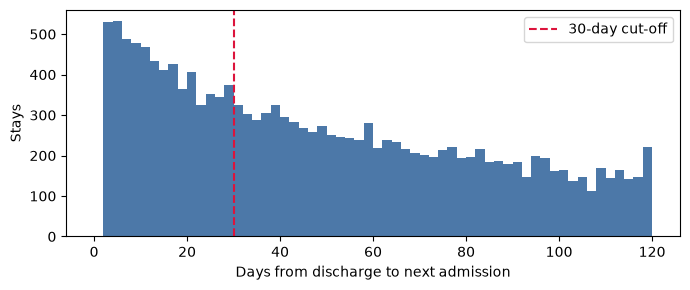

In [45]:
ip_stays["NEXT_ADMSN_DT"] = ip_stays.groupby("DESYNPUF_ID")["ADMSN_DT"].shift(-1)
ip_stays["DAYS_TO_NEXT_ADMIT"] = (ip_stays["NEXT_ADMSN_DT"] - ip_stays["DSCHRG_DT"]).dt.days
ip_stays["READMIT_30"] = (ip_stays["DAYS_TO_NEXT_ADMIT"] <= 30).astype("int8")   # NaN <= 30 is False -> 0
ip_stays = ip_stays.drop(columns="NEXT_ADMSN_DT")

assert (ip_stays["DAYS_TO_NEXT_ADMIT"].dropna() >= 0).all()
print("Stays with a later admission by the same patient:", int(ip_stays["DAYS_TO_NEXT_ADMIT"].notna().sum()),
      "of", len(ip_stays))
print("READMIT_30 (before any eligibility filter):", ip_stays["READMIT_30"].value_counts().to_dict(),
      f"-> {ip_stays['READMIT_30'].mean():.1%}")
print("DAYS_TO_NEXT_ADMIT summary (days):")
display(ip_stays["DAYS_TO_NEXT_ADMIT"].describe().round(1).to_frame().T)

import matplotlib.pyplot as plt
_d = ip_stays["DAYS_TO_NEXT_ADMIT"].dropna()
plt.figure(figsize=(7, 3))
plt.hist(_d[_d <= 120], bins=range(0, 122, 2), color="#4c78a8")
plt.axvline(30, color="crimson", ls="--", label="30-day cut-off")
plt.xlabel("Days from discharge to next admission"); plt.ylabel("Stays"); plt.legend(); plt.tight_layout(); plt.show()
del _d

The histogram is nearly flat on the left of the cut-off: the number of next admissions per 2-day bin right after
discharge is about the same as 60 days later. Real hospital data usually has a bump just after discharge, so the
readmission signal in this synthetic data is weak; this is a property of DE-SynPUF and not a cleaning error.

### 4.4 Which stays can be an *index* stay? (eligibility)

A stay is a valid example for "will this patient be readmitted within 30 days?" only if the outcome can actually be
observed. We flag three situations; `ELIGIBLE_INDEX = 1` only if none applies. Every flag is kept as a column so the
choice can be revisited.

1. **`DIED_IN_STAY`**: the patient's death month is on or before the discharge month. Death dates are the 1st of the
   month, so we cannot tell whether the death was inside the stay or just after it; a patient who dies in the
   stay cannot be readmitted, so they are excluded. (Month granularity means this may also drop a stay where the
   patient left alive and died later that same month.)
2. **`CENSORED_NO_FOLLOWUP`**: discharge later than `STUDY_END - 30 days` (after 2010-12-01). The data end on
   2010-12-31, so a 0 for these stays could simply mean the window was not fully observed.
3. **`DIED_30D_NO_READMIT`**: the patient died within 30 days after discharge **without** a readmission. They
   could not be readmitted, so `READMIT_30 = 0` is not a real "no readmission". Stays where the patient was readmitted
   and *then* died are kept: the outcome (1) was observed. Because the death date is only the 1st of a month, this
   flag is approximate.

*Alternative for flag 3:* keep these stays and label them 1 ("bad outcome") or 0. We exclude them as the standard,
conservative choice; the flag allows the team to test the alternative later.

In [46]:
ip_stays = ip_stays.merge(bene_static[["DESYNPUF_ID", "DEATH_DT"]], on="DESYNPUF_ID", how="left")
_has_death = ip_stays["DEATH_DT"].notna()

ip_stays["DIED_IN_STAY"] = (_has_death & (_month_idx(ip_stays["DEATH_DT"]) <= _month_idx(ip_stays["DSCHRG_DT"]))).astype("int8")
ip_stays["CENSORED_NO_FOLLOWUP"] = (ip_stays["DSCHRG_DT"] > STUDY_END - pd.DateOffset(days=30)).astype("int8")
_days_to_death = (ip_stays["DEATH_DT"] - ip_stays["DSCHRG_DT"]).dt.days
ip_stays["DIED_30D_NO_READMIT"] = (_has_death & (ip_stays["DIED_IN_STAY"] == 0) & (_days_to_death <= 30)
                                   & (ip_stays["READMIT_30"] == 0)).astype("int8")
ip_stays = ip_stays.drop(columns="DEATH_DT")

_flags = ["DIED_IN_STAY", "CENSORED_NO_FOLLOWUP", "DIED_30D_NO_READMIT"]
ip_stays["ELIGIBLE_INDEX"] = (ip_stays[_flags].sum(axis=1) == 0).astype("int8")

print("Stays flagged by each rule (a stay can have more than one):")
display(ip_stays[_flags].sum().to_frame("stays"))

# waterfall: how many stays each rule removes in turn
_left = len(ip_stays)
for _f in _flags:
    _keep = ip_stays[_flags[:_flags.index(_f) + 1]].sum(axis=1) == 0
    log_step("ip_stays", f"index eligibility: exclude {_f}", _left, int(_keep.sum()))
    _left = int(_keep.sum())
assert _left == ip_stays["ELIGIBLE_INDEX"].sum()
print(f"\nEligible index stays: {_left:,} of {len(ip_stays):,}")
print("Readmission rate among stays EXCLUDED as censored (shows why a 0 there is unreliable):",
      f"{ip_stays.loc[ip_stays['CENSORED_NO_FOLLOWUP'] == 1, 'READMIT_30'].mean():.1%}",
      "vs eligible:", f"{ip_stays.loc[ip_stays['ELIGIBLE_INDEX'] == 1, 'READMIT_30'].mean():.1%}")

Stays flagged by each rule (a stay can have more than one):


,stays
DIED_IN_STAY,4
CENSORED_NO_FOLLOWUP,310
DIED_30D_NO_READMIT,85


[ip_stays] index eligibility: exclude DIED_IN_STAY: 64,273 -> 64,269 rows (4 removed)
[ip_stays] index eligibility: exclude CENSORED_NO_FOLLOWUP: 64,269 -> 63,959 rows (310 removed)
[ip_stays] index eligibility: exclude DIED_30D_NO_READMIT: 63,959 -> 63,874 rows (85 removed)

Eligible index stays: 63,874 of 64,273
Readmission rate among stays EXCLUDED as censored (shows why a 0 there is unreliable): 0.0% vs eligible: 9.6%


The censored stays have a readmission rate of essentially zero: no next admission is recorded in the last weeks of
the data, so a 0 there means "not observed", not "not readmitted". Keeping them would bias the label downward.
`ip_stays` (all stays, with flags) is saved in section 5; the model uses only `ELIGIBLE_INDEX == 1`.

### 4.5 Building `readmit_df`: features known at admission/discharge

**Stay features** come from the stay itself: length of stay, number of claims, diagnosis/procedure counts, DRG,
admitting and principal diagnosis, and total payment.

**Patient features** come from `bene_static` (age at admission, sex, race, state) and from `bene_year` for the
**discharge year** (ESRD, the 11 chronic-condition flags, `N_CHRONIC`, months of coverage).

**What we leave out on purpose (leakage).** `bene_year` also has annual dollar totals (`MEDREIMB_IP`, `BENRES_IP`,
`PPPYMT_IP`, the OP and carrier versions). The same-year totals **include the stay we are predicting about** and
any stays after it (including the readmission), so they would leak the answer. We do not use them; prior-year
totals would be legitimate but are missing for every 2008 stay and are already summarized by the prior-utilization
features below.

**Prior-utilization features** use only data **strictly before the admission date**: count of earlier stays in
the last 365 days (by discharge date), and count/payment of earlier outpatient visits (and ER visits) in the last
30 or 365 days. They are computed with one merge per table and a date filter, not a loop over patients. Since our data
start on 2008-01-01, patients admitted early in 2008 have little visible history, so we add
`OBS_HISTORY_DAYS` (days of data before admission, capped at 365) so a model can tell "no prior visits" from
"no history available".

In [47]:
_idx = ip_stays.loc[ip_stays["ELIGIBLE_INDEX"] == 1].copy()

# patient features
_idx = _idx.merge(bene_static[["DESYNPUF_ID", "BIRTH_DT", "SEX", "RACE", "SP_STATE_CODE"]], on="DESYNPUF_ID", how="left")
_idx["AGE"] = ((_idx["ADMSN_DT"] - _idx["BIRTH_DT"]).dt.days / 365.25).round(1)
_idx["DSCHRG_YEAR"] = _idx["DSCHRG_DT"].dt.year.astype("int16")
_by_cols = ["DESYNPUF_ID", "YEAR", "ESRD", "N_CHRONIC", "ZERO_COVERAGE",
            "BENE_HI_CVRAGE_TOT_MONS", "BENE_SMI_CVRAGE_TOT_MONS", "BENE_HMO_CVRAGE_TOT_MONS", "PLAN_CVRG_MOS_NUM"]
_by_cols += [c for c in bene_year.columns if c.startswith("SP_") and c != "SP_STATE_CODE"]
_idx = _idx.merge(bene_year[_by_cols].rename(columns={"YEAR": "DSCHRG_YEAR"}), on=["DESYNPUF_ID", "DSCHRG_YEAR"], how="left")
_idx["OBS_HISTORY_DAYS"] = (_idx["ADMSN_DT"] - STUDY_START).dt.days.clip(0, 365).astype("int16")
print("Index stays:", len(_idx), "| lost any rows in the merges?", len(_idx) != int(ip_stays["ELIGIBLE_INDEX"].sum()))
print("Age at admission:", _idx["AGE"].describe().round(1).to_dict())

Index stays: 63874 | lost any rows in the merges? False
Age at admission: {'count': 63874.0, 'mean': 73.7, 'std': 13.3, 'min': 24.6, '25%': 67.6, '50%': 75.0, '75%': 82.7, 'max': 101.7}


In [48]:
# prior inpatient stays: earlier stays (discharged strictly before this admission) within 365 days
_ref = _idx[["STAY_ID", "DESYNPUF_ID", "ADMSN_DT"]]
_prev = _ref.merge(ip_stays[["DESYNPUF_ID", "STAY_ID", "DSCHRG_DT"]].rename(columns={"STAY_ID": "PREV_STAY_ID"}),
                   on="DESYNPUF_ID")
_prev["days_before"] = (_prev["ADMSN_DT"] - _prev["DSCHRG_DT"]).dt.days
_prev = _prev[(_prev["days_before"] >= 1) & (_prev["days_before"] <= 365)]
_prior_ip = _prev.groupby("STAY_ID").size().rename("PRIOR_IP_STAYS_365")

# prior outpatient visits: claims dated strictly before the admission date
_op_small = op_clean.loc[op_clean["DESYNPUF_ID"].isin(_idx["DESYNPUF_ID"]),
                         ["DESYNPUF_ID", "CLM_FROM_DT", "CLM_PMT_AMT", "ER_VISIT"]]
_op = _ref.merge(_op_small, on="DESYNPUF_ID")
_op["days_before"] = (_op["ADMSN_DT"] - _op["CLM_FROM_DT"]).dt.days
_op = _op[(_op["days_before"] >= 1) & (_op["days_before"] <= 365)].copy()
_op["in30"] = _op["days_before"] <= 30
_op["pmt"] = _op["CLM_PMT_AMT"].astype("float64")
_op["er"] = _op["ER_VISIT"].astype("int8")
_prior_op = _op.groupby("STAY_ID").agg(
    PRIOR_OP_VISITS_365=("DESYNPUF_ID", "size"),
    PRIOR_OP_VISITS_30=("in30", "sum"),
    PRIOR_OP_PMT_365=("pmt", "sum"),
    PRIOR_ER_VISITS_365=("er", "sum"),
)

readmit_df = _idx.merge(_prior_ip, left_on="STAY_ID", right_index=True, how="left") \
                 .merge(_prior_op, left_on="STAY_ID", right_index=True, how="left")
_prior_cols = ["PRIOR_IP_STAYS_365", "PRIOR_OP_VISITS_30", "PRIOR_OP_VISITS_365", "PRIOR_OP_PMT_365", "PRIOR_ER_VISITS_365"]
# no earlier record in the window = zero earlier use (these are counts, so a missing merge result means 0)
readmit_df[_prior_cols] = readmit_df[_prior_cols].fillna(0)
for _c in ["PRIOR_IP_STAYS_365", "PRIOR_OP_VISITS_30", "PRIOR_OP_VISITS_365", "PRIOR_ER_VISITS_365"]:
    readmit_df[_c] = readmit_df[_c].astype("int16")
del _ref, _prev, _op, _op_small, _prior_ip, _prior_op, _idx

print("Prior-utilization features (index stays):")
display(readmit_df[_prior_cols].describe().round(1).T[["mean", "50%", "max"]])
print("Share of index stays with no visible prior outpatient visit in 365 days:",
      f"{(readmit_df['PRIOR_OP_VISITS_365'] == 0).mean():.1%}",
      "| of those, stays with <365 days of history:",
      f"{((readmit_df['PRIOR_OP_VISITS_365'] == 0) & (readmit_df['OBS_HISTORY_DAYS'] < 365)).mean():.1%} of all index stays")

Prior-utilization features (index stays):


,mean,50%,max
PRIOR_IP_STAYS_365,0.6,0.0,8.0
PRIOR_OP_VISITS_30,0.4,0.0,7.0
PRIOR_OP_VISITS_365,4.0,3.0,35.0
PRIOR_OP_PMT_365,1463.5,390.0,68610.0
PRIOR_ER_VISITS_365,0.3,0.0,7.0


Share of index stays with no visible prior outpatient visit in 365 days: 21.4% | of those, stays with <365 days of history: 13.4% of all index stays


**Caveat: chronic-condition flags.** The `SP_*` flags and `N_CHRONIC` are **annual** summaries for the discharge year.
A condition that was first diagnosed *after* this stay (even during the readmission) can already be set to 1, so
these features may partly reflect information from after the admission. In a real deployment we would only know
conditions diagnosed before admission. We keep them because they are the only comorbidity information in the data,
but the team should be careful when interpreting their importance. Section 4.6 measures how much this matters by
comparing against the *previous* year's flags, which cannot contain post-admission information.

### 4.6 Final table: class balance, sanity check, missing values

In [49]:
_cols_front = ["STAY_ID", "DESYNPUF_ID", "ADMSN_DT", "DSCHRG_DT", "READMIT_30", "DAYS_TO_NEXT_ADMIT"]
readmit_df = readmit_df[_cols_front + [c for c in readmit_df.columns if c not in _cols_front]]
readmit_df = readmit_df.drop(columns=["BIRTH_DT", "DSCHRG_YEAR", "YEAR"], errors="ignore")
readmit_df = readmit_df.drop(columns=["DIED_IN_STAY", "CENSORED_NO_FOLLOWUP", "DIED_30D_NO_READMIT", "ELIGIBLE_INDEX"])
readmit_df = readmit_df.reset_index(drop=True)

print("readmit_df shape:", readmit_df.shape)
_vc = readmit_df["READMIT_30"].value_counts().sort_index()
display(pd.DataFrame({"stays": _vc, "share": (_vc / len(readmit_df)).round(3)}))

# sanity: readmission rate should move sensibly with age and illness burden
_age_bin = pd.cut(readmit_df["AGE"], [0, 65, 75, 85, 120], right=False)
_chr_bin = pd.cut(readmit_df["N_CHRONIC"], [-1, 2, 4, 6, 11], labels=["0-2", "3-4", "5-6", "7+"])
print("Readmission rate by age group:")
display(readmit_df.groupby(_age_bin, observed=True)["READMIT_30"].agg(stays="size", rate="mean").round(3))
print("Readmission rate by number of chronic conditions:")
display(readmit_df.groupby(_chr_bin, observed=True)["READMIT_30"].agg(stays="size", rate="mean").round(3))
print("Readmission rate by prior inpatient stays in last 365 days:")
display(readmit_df.groupby(readmit_df["PRIOR_IP_STAYS_365"].clip(upper=3), observed=True)["READMIT_30"]
        .agg(stays="size", rate="mean").round(3))

readmit_df shape: (63874, 46)


,stays,share
READMIT_30,,
0,57773,0.904
1,6101,0.096


Readmission rate by age group:


,stays,rate
AGE,,
"[0, 65)",11055,0.101
"[65, 75)",20847,0.087
"[75, 85)",20132,0.098
"[85, 120)",11840,0.101


Readmission rate by number of chronic conditions:


,stays,rate
N_CHRONIC,,
0-2,7164,0.022
3-4,14438,0.046
5-6,20067,0.091
7+,22205,0.156


Readmission rate by prior inpatient stays in last 365 days:


,stays,rate
PRIOR_IP_STAYS_365,,
0,40241,0.085
1,14492,0.103
2,5636,0.122
3,3505,0.145


Age shows almost no pattern. Prior inpatient use has a plausible gradient, which is typical of real readmission data.
The number of chronic conditions shows a much *steeper* gradient than anything else, which is suspicious: the
same-year flags can be switched on by the readmission itself. To separate real risk from leakage, we compare against
the chronic-condition count from the **previous calendar year** (`N_CHRONIC_PREV_YEAR`), which was fixed before the
admission and so cannot leak. It only exists for patients with a prior-year beneficiary record (not for 2008
discharges), so it is left as `NaN` where unavailable.

In [50]:
_prev = (bene_year[["DESYNPUF_ID", "YEAR", "N_CHRONIC"]]
         .rename(columns={"YEAR": "_PY", "N_CHRONIC": "N_CHRONIC_PREV_YEAR"}))
readmit_df = (readmit_df.assign(_PY=readmit_df["DSCHRG_DT"].dt.year - 1)
              .merge(_prev, on=["DESYNPUF_ID", "_PY"], how="left").drop(columns="_PY"))
print(f"Index stays with a prior-year record: {readmit_df['N_CHRONIC_PREV_YEAR'].notna().mean():.1%}")

_both = readmit_df[readmit_df["N_CHRONIC_PREV_YEAR"].notna()]
_bins, _labels = [-1, 2, 4, 6, 11], ["0-2", "3-4", "5-6", "7+"]
display(pd.DataFrame({
    "same-year flags": _both.groupby(pd.cut(_both["N_CHRONIC"], _bins, labels=_labels), observed=True)["READMIT_30"].mean(),
    "previous-year flags": _both.groupby(pd.cut(_both["N_CHRONIC_PREV_YEAR"], _bins, labels=_labels), observed=True)["READMIT_30"].mean(),
}).round(3).rename_axis("chronic conditions"))
del _prev, _both

Index stays with a prior-year record: 59.5%


,same-year flags,previous-year flags
chronic conditions,,
0-2,0.016,0.035
3-4,0.034,0.050
5-6,0.063,0.074
7+,0.113,0.100


**Finding.** On the same set of stays, the readmission rate still rises clearly with the *previous-year* chronic count,
so comorbidity burden is a real risk factor. But the gradient with the *same-year* flags is noticeably steeper — the
extra steepness is the part inflated by post-admission information. Recommendation for modeling: prefer
`N_CHRONIC_PREV_YEAR` (leakage-free, but missing for 2008 discharges), or use the same-year `SP_*` flags while
reporting this caveat and comparing a model with and without them.

**Missing values.** Check what is missing in the final table and handle it before saving.

In [51]:
display(missing_report(readmit_df, top=10))

,pct_missing
DAYS_TO_NEXT_ADMIT,58.5
N_CHRONIC_PREV_YEAR,40.5
ADMTNG_ICD9_DGNS_CD,0.8
ADMSN_DT,0.0
DSCHRG_DT,0.0
READMIT_30,0.0
DESYNPUF_ID,0.0
PRVDR_NUM,0.0
CLM_DRG_CD,0.0
DRG_UNGROUPED,0.0


Reading the table above: `DAYS_TO_NEXT_ADMIT` is missing by design for stays with no later admission; it is
**a by-product of the label and must not be used as a feature** (it would leak the target), so it is the first thing
to drop before modeling. Diagnosis/DRG codes can be blank on some claims, and sex/race/state come from the
beneficiary file. We replace missing *codes* with the explicit text `"MISSING"` (a missing code is information, not an
error, and categorical encoders cannot handle `NaN`), and we leave numerical gaps visible if any remain.

In [52]:
for _c in ["CLM_DRG_CD", "ADMTNG_ICD9_DGNS_CD", "ICD9_DGNS_CD_1", "PRVDR_NUM", "SP_STATE_CODE"]:
    readmit_df[_c] = readmit_df[_c].astype("object").where(readmit_df[_c].notna(), "MISSING")
_by_design = ["DAYS_TO_NEXT_ADMIT", "N_CHRONIC_PREV_YEAR"]
assert readmit_df.drop(columns=_by_design).isna().sum().sum() == 0, "unexpected missing values"
print("Missing values left (excluding DAYS_TO_NEXT_ADMIT and N_CHRONIC_PREV_YEAR, which are missing by design):",
      int(readmit_df.drop(columns=_by_design).isna().sum().sum()))
print("Distinct codes: DRG", readmit_df["CLM_DRG_CD"].nunique(), "| admitting dx", readmit_df["ADMTNG_ICD9_DGNS_CD"].nunique(),
      "| principal dx", readmit_df["ICD9_DGNS_CD_1"].nunique(), "(high-cardinality: group or encode before modeling)")
display(readmit_df.head(3).T.head(30))

Missing values left (excluding DAYS_TO_NEXT_ADMIT and N_CHRONIC_PREV_YEAR, which are missing by design): 0
Distinct codes: DRG 739 | admitting dx 2259 | principal dx 2698 (high-cardinality: group or encode before modeling)


,0,1,2
STAY_ID,1,2,3
DESYNPUF_ID,00013D2EFD8E45D1,00016F745862898F,00016F745862898F
ADMSN_DT,2010-03-12 00:00:00,2009-04-12 00:00:00,2009-08-31 00:00:00
DSCHRG_DT,2010-03-13 00:00:00,2009-04-18 00:00:00,2009-09-02 00:00:00
READMIT_30,0,0,1
DAYS_TO_NEXT_ADMIT,NaN,135.0,15.0
PRVDR_NUM,2600GD,3900MB,3900HM
CLM_DRG_CD,217,201,750
DRG_UNGROUPED,False,False,False
ADMTNG_ICD9_DGNS_CD,4580,7866,6186


**Generalizing diagnosis codes (concept hierarchy).** ICD-9 codes are hierarchical: the first three characters name
the disease category and the rest add detail (`4280` = congestive heart failure, unspecified → category `428` = heart
failure). Thousands of distinct codes are too many to one-hot encode, so we add a category column one level up the
hierarchy. External-cause codes (`E…`) use four characters because their category is `E` + 3 digits. The original
codes are kept, so no detail is lost.

In [53]:
def _icd9_category(s):
    s = s.astype(str)
    return s.where(s == "MISSING", np.where(s.str.startswith("E"), s.str[:4], s.str[:3]))

readmit_df["DX1_CAT"] = _icd9_category(readmit_df["ICD9_DGNS_CD_1"])
readmit_df["ADMTNG_DX_CAT"] = _icd9_category(readmit_df["ADMTNG_ICD9_DGNS_CD"])
display(pd.DataFrame({
    "distinct codes": [readmit_df["ICD9_DGNS_CD_1"].nunique(), readmit_df["ADMTNG_ICD9_DGNS_CD"].nunique()],
    "distinct categories": [readmit_df["DX1_CAT"].nunique(), readmit_df["ADMTNG_DX_CAT"].nunique()],
}, index=["principal diagnosis", "admitting diagnosis"]))
print("Most common principal-diagnosis categories:")
display(readmit_df["DX1_CAT"].value_counts().head(5).to_frame("stays"))

,distinct codes,distinct categories
principal diagnosis,2698,646
admitting diagnosis,2259,574


Most common principal-diagnosis categories:


,stays
DX1_CAT,
428,3016
038,2380
715,2356
486,2347
427,2229


**Section summary**

* **Cross-table checks:** every inpatient claim belongs to a known patient and matches a beneficiary row on the
  discharge year; no claim starts after the death month (death dates are month-level, so all comparisons use
  months). Zero-coverage patient-years are kept and flagged.
* **Stays:** claims were merged into hospital stays (overlap, or admission within `TRANSFER_GAP_DAYS = 1` day of the
  previous discharge; CMS-style transfer rule). The stay table `ip_stays` keeps min admit, max discharge, summed
  payment, and codes/DRG from the first claim. The counts above show how many claims merged.
* **Label:** `DAYS_TO_NEXT_ADMIT` = next stay's admission minus this discharge; `READMIT_30 = 1` if <= 30 days.
* **Eligibility (`ELIGIBLE_INDEX`):** exclude stays where the patient died in the stay (month-level), stays with
  discharge after 2010-12-01 (incomplete 30-day follow-up), and stays where the patient died within 30 days without a
  readmission. The flags are kept in `ip_stays` so these choices can be changed.
* **`readmit_df`:** one row per eligible index stay, with stay features, patient features (age, sex, race, state), the
  discharge-year chronic flags and coverage, plus prior-utilization counts built only from earlier dates. Same-year
  annual dollar totals are excluded (they contain the outcome), same-year chronic flags carry a caveat (a
  leakage-free `N_CHRONIC_PREV_YEAR` is provided), and
  `DAYS_TO_NEXT_ADMIT` must be dropped before modeling because it defines the label.
* **Remaining issues for the team:** weak signal in synthetic data, high-cardinality code columns, class imbalance.

## 5. Data profile: course preprocessing checklist

Before saving, we describe the final modeling table `readmit_df` the way the course does (Ch. 2–3): what *type* each
attribute is, its summary statistics, which values the 1.5 × IQR rule calls outliers, and whether any attributes are
redundant. Nothing in this section changes the data; it documents it and backs up the decisions made earlier.

### 5.1 Attribute types
Each column is labelled with its course attribute type. **Asymmetric binary** means the 1 is the rare, interesting
case (having a disease) and two 0s are not a meaningful match; **symmetric binary** means both values are equally
informative (sex). Numeric attributes here are all **ratio-scaled** (they have a true zero: 0 days, $0, 0 visits).
IDs and dates are not features; they are excluded before modeling.

In [54]:
_id_cols = ["STAY_ID", "DESYNPUF_ID"]
_date_cols = ["ADMSN_DT", "DSCHRG_DT"]
_target = ["READMIT_30"]
_label_byproduct = ["DAYS_TO_NEXT_ADMIT"]
_sym_binary = ["SEX"]
_asym_binary = [c for c in readmit_df.columns if c.startswith("SP_") and c != "SP_STATE_CODE"] + \
               ["ESRD", "DRG_UNGROUPED", "ANY_PMT_NEGATIVE", "ADMSN_BEFORE_STUDY", "ZERO_COVERAGE"]
_nominal = ["RACE", "SP_STATE_CODE", "PRVDR_NUM", "CLM_DRG_CD", "ADMTNG_ICD9_DGNS_CD", "ICD9_DGNS_CD_1",
            "DX1_CAT", "ADMTNG_DX_CAT"]
_continuous = ["TOTAL_PMT", "PRIOR_OP_PMT_365", "AGE"]
_numeric = [c for c in readmit_df.columns
            if c not in _id_cols + _date_cols + _target + _label_byproduct + _sym_binary + _asym_binary + _nominal]

def _attr_type(c):
    if c in _id_cols: return "identifier (not a feature)"
    if c in _date_cols: return "date (not a feature)"
    if c in _target: return "target: asymmetric binary"
    if c in _label_byproduct: return "label by-product (drop: leakage)"
    if c in _sym_binary: return "binary, symmetric"
    if c in _asym_binary: return "binary, asymmetric"
    if c in _nominal: return "nominal"
    return "numeric, ratio-scaled"

attr_types = pd.DataFrame({
    "type": [_attr_type(c) for c in readmit_df.columns],
    "discrete/continuous": ["continuous" if c in _continuous else
                            ("—" if c in _id_cols + _date_cols else "discrete") for c in readmit_df.columns],
    "distinct values": [readmit_df[c].nunique() for c in readmit_df.columns],
}, index=readmit_df.columns)
print(f"readmit_df: N = {len(readmit_df):,} objects (index stays) x {readmit_df.shape[1]} attributes")
display(attr_types["type"].value_counts().to_frame("attributes"))
display(attr_types)

readmit_df: N = 63,874 objects (index stays) x 49 attributes


,attributes
type,
"numeric, ratio-scaled",18
"binary, asymmetric",16
nominal,8
identifier (not a feature),2
date (not a feature),2
target: asymmetric binary,1
label by-product (drop: leakage),1
"binary, symmetric",1


,type,discrete/continuous,distinct values
STAY_ID,identifier (not a feature),—,63874
DESYNPUF_ID,identifier (not a feature),—,37658
ADMSN_DT,date (not a feature),—,1091
DSCHRG_DT,date (not a feature),—,1066
READMIT_30,target: asymmetric binary,discrete,2
DAYS_TO_NEXT_ADMIT,label by-product (drop: leakage),discrete,893
PRVDR_NUM,nominal,discrete,2666
CLM_DRG_CD,nominal,discrete,739
DRG_UNGROUPED,"binary, asymmetric",discrete,2
ADMTNG_ICD9_DGNS_CD,nominal,discrete,2259


There are **no ordinal** attributes in the raw data. Ordinal versions can be created later by discretizing (e.g. age
groups) if a method needs them, such as association-rule mining.

### 5.2 Summary statistics and the 1.5 × IQR outlier rule
For every numeric attribute: the five-number summary (min, Q1, median, Q3, max), mean, mode, midrange, standard
deviation, and the share of values outside the IQR fences `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`.

In [55]:
_num = readmit_df[_numeric].astype("float64")
_q1, _q3 = _num.quantile(0.25), _num.quantile(0.75)
_iqr = _q3 - _q1
numeric_summary = pd.DataFrame({
    "min": _num.min(), "Q1": _q1, "median": _num.median(), "Q3": _q3, "max": _num.max(),
    "mean": _num.mean(), "mode": _num.mode().iloc[0], "midrange": (_num.min() + _num.max()) / 2,
    "std": _num.std(), "IQR": _iqr,
    "% outliers (1.5×IQR)": ((_num < _q1 - 1.5 * _iqr) | (_num > _q3 + 1.5 * _iqr)).mean() * 100,
}).round(2).sort_values("% outliers (1.5×IQR)", ascending=False)
display(numeric_summary)

,min,Q1,median,Q3,max,mean,mode,midrange,std,IQR,% outliers (1.5×IQR)
PLAN_CVRG_MOS_NUM,0.0,9.0,12.0,12.0,12.0,9.34,12.0,6.00,4.71,3.0,20.56
PRIOR_OP_PMT_365,-90.0,30.0,390.0,1370.0,68610.0,1463.54,0.0,34260.00,3768.29,1340.0,9.97
TOTAL_PMT,-8000.0,4000.0,7000.0,12000.0,129000.0,9941.05,4000.0,60500.00,9953.65,8000.0,7.23
LOS_DAYS,0.0,2.0,4.0,7.0,59.0,5.80,3.0,29.50,5.86,5.0,7.22
PRIOR_IP_STAYS_365,0.0,0.0,0.0,1.0,8.0,0.60,0.0,4.00,0.97,1.0,5.49
N_PRCDR,0.0,0.0,1.0,2.0,6.0,1.43,0.0,3.00,1.74,2.0,4.82
N_DX,1.0,7.0,9.0,9.0,10.0,8.05,9.0,5.50,1.87,2.0,3.95
AGE,24.6,67.6,75.0,82.7,101.7,73.74,68.1,63.15,13.26,15.1,3.94
N_CLAIMS,1.0,1.0,1.0,1.0,5.0,1.04,1.0,3.00,0.21,0.0,3.44
PRIOR_OP_VISITS_365,0.0,1.0,3.0,6.0,35.0,3.97,0.0,17.50,4.03,5.0,3.05


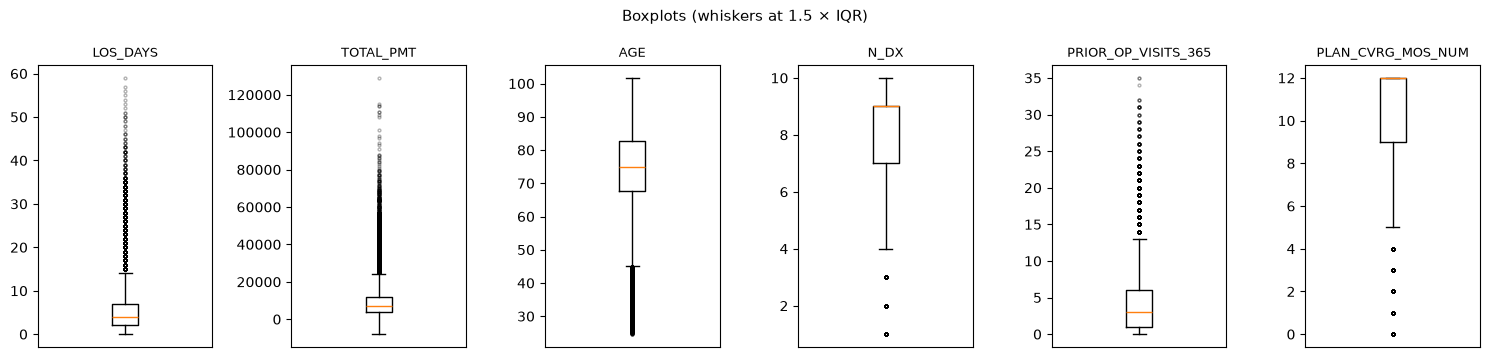

In [56]:
import matplotlib.pyplot as plt

_box_cols = ["LOS_DAYS", "TOTAL_PMT", "AGE", "N_DX", "PRIOR_OP_VISITS_365", "PLAN_CVRG_MOS_NUM"]
fig, axes = plt.subplots(1, len(_box_cols), figsize=(15, 3.6))
for _ax, _c in zip(axes, _box_cols):
    _ax.boxplot(readmit_df[_c].dropna(), whis=1.5, flierprops={"markersize": 2, "alpha": 0.3})
    _ax.set_title(_c, fontsize=9)
    _ax.set_xticks([])
fig.suptitle("Boxplots (whiskers at 1.5 × IQR)", fontsize=11)
plt.tight_layout()
plt.show()

**Reading the outlier table.**
* `TOTAL_PMT`, `LOS_DAYS`, `PRIOR_OP_PMT_365` and the prior-visit counts have a few percent of values beyond the
  upper fence. These are the long right tails typical of healthcare costs and utilization (a few patients are very
  sick), not data-entry errors: earlier sections checked that dates and amounts are valid. Removing them would
  remove exactly the high-risk patients we want to predict, so they are **kept**. For distance-based or linear models,
  a `log1p` transform at modeling time tames the skew.
* The rule misfires on bounded or mostly-constant counts. For `BENE_SMI_CVRAGE_TOT_MONS` and `N_CLAIMS`, Q1 = Q3, so
  IQR = 0 and *every* value that isn't the typical one (any coverage below 12 months, any stay with 2+ claims) is
  called an outlier. For `PLAN_CVRG_MOS_NUM` (drug-plan months, 0–12) the lower fence is 4.5 months, so the ~20 % of
  patients with little or no drug coverage are flagged, though they are an ordinary group, not errors. The 1.5 × IQR
  rule assumes a spread-out, roughly continuous distribution and should not be applied blindly to counts like these.

### 5.3 Redundancy (data integration)
Two attributes are redundant if one can be (nearly) derived from the other. The course tests numeric pairs with the
**correlation coefficient r** and categorical pairs with the **χ² test**, summarized as **Cramér's V** (0 = independent,
1 = one fully determines the other). Correlation shows association, not causation.

Numeric/binary pairs checked: 560; pairs with |r| >= 0.7: 0
Strongest correlations:


,attribute 1,attribute 2,r,|r|
0,PRIOR_OP_VISITS_365,PRIOR_OP_PMT_365,0.572,0.572
1,N_CHRONIC,SP_CHF,0.539,0.539
2,N_CHRONIC,N_CHRONIC_PREV_YEAR,0.537,0.537
3,N_CHRONIC,SP_CHRNKIDN,0.527,0.527
4,N_CHRONIC,SP_DIABETES,0.520,0.520
5,N_CHRONIC,SP_COPD,0.519,0.519
6,PRIOR_OP_VISITS_365,PRIOR_ER_VISITS_365,0.515,0.515
7,BENE_HI_CVRAGE_TOT_MONS,BENE_SMI_CVRAGE_TOT_MONS,0.505,0.505


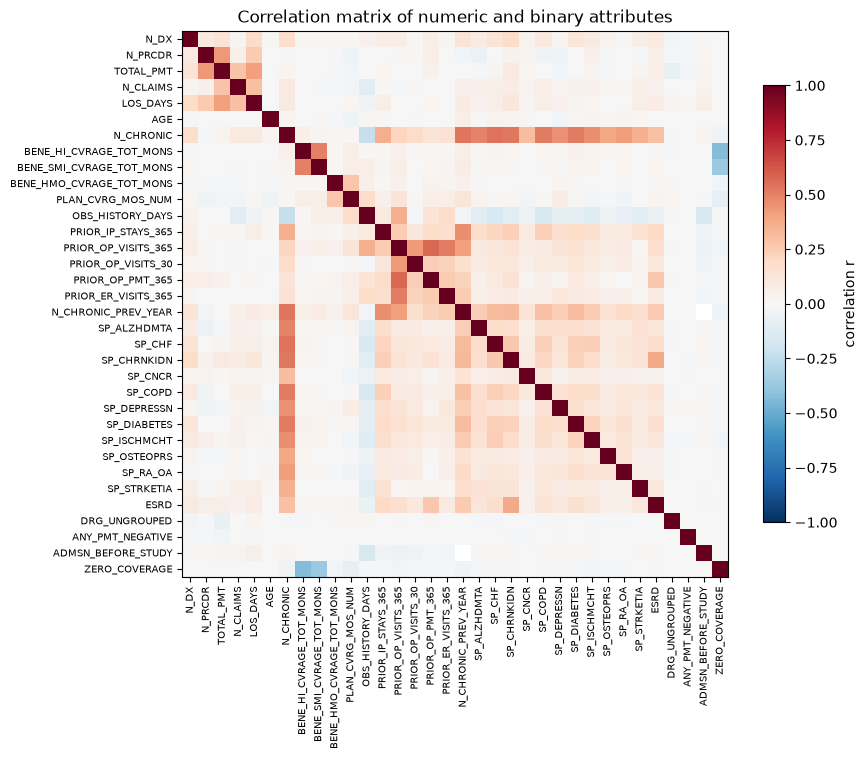

In [57]:
_corr_cols = _numeric + [c for c in _asym_binary + _sym_binary if pd.api.types.is_numeric_dtype(readmit_df[c])
                         or readmit_df[c].dtype == bool]
_corr = readmit_df[_corr_cols].astype("float64").corr()
_pairs = (_corr.where(np.triu(np.ones(_corr.shape, dtype=bool), k=1)).stack()
          .rename("r").reset_index().rename(columns={"level_0": "attribute 1", "level_1": "attribute 2"}))
_pairs["|r|"] = _pairs["r"].abs()
print(f"Numeric/binary pairs checked: {len(_pairs):,}; pairs with |r| >= 0.7: {(_pairs['|r|'] >= 0.7).sum()}")
print("Strongest correlations:")
display(_pairs.sort_values("|r|", ascending=False).head(8).round(3).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, 7.5))
_im = ax.imshow(_corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(_corr_cols)), _corr_cols, rotation=90, fontsize=7)
ax.set_yticks(range(len(_corr_cols)), _corr_cols, fontsize=7)
fig.colorbar(_im, ax=ax, shrink=0.8, label="correlation r")
ax.set_title("Correlation matrix of numeric and binary attributes")
plt.tight_layout()
plt.show()

In [58]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p, _, _ = chi2_contingency(table)
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))), p

_cat_pairs = [("SEX", "RACE"), ("SEX", "SP_STATE_CODE"), ("RACE", "SP_STATE_CODE"), ("RACE", "ESRD"),
              ("DX1_CAT", "ADMTNG_DX_CAT")]
_rows = []
for _a, _b in _cat_pairs:
    _v, _p = cramers_v(readmit_df[_a], readmit_df[_b])
    _rows.append({"attribute 1": _a, "attribute 2": _b, "Cramér's V": round(_v, 3), "χ² p-value": f"{_p:.1e}"})
display(pd.DataFrame(_rows))
print("Admitting and principal diagnosis identical in",
      f"{(readmit_df['ADMTNG_ICD9_DGNS_CD'] == readmit_df['ICD9_DGNS_CD_1']).mean():.1%} of stays")

_sp = [c for c in _asym_binary if c.startswith("SP_")]
print("N_CHRONIC equals the sum of the 11 SP_* flags in",
      f"{(readmit_df[_sp].sum(axis=1) == readmit_df['N_CHRONIC']).mean():.0%} of rows (derived attribute)")

,attribute 1,attribute 2,Cramér's V,χ² p-value
0,SEX,RACE,0.019,6.0e-05
1,SEX,SP_STATE_CODE,0.047,1.1e-10
2,RACE,SP_STATE_CODE,0.236,0.0e+00
3,RACE,ESRD,0.022,1.5e-06
4,DX1_CAT,ADMTNG_DX_CAT,0.337,0.0e+00


Admitting and principal diagnosis identical in 20.7% of stays
N_CHRONIC equals the sum of the 11 SP_* flags in 100% of rows (derived attribute)


**Reading the redundancy checks.**
* No pair of numeric attributes is strongly correlated (|r| ≥ 0.7), so no column is a near-copy of another.
* Among categorical attributes the χ² tests are often "significant" (with 63k rows even tiny effects give small
  p-values), but Cramér's V is low, so the dependence is weak. Admitting and principal diagnosis are only moderately
  related and usually differ, so both carry information and both are kept.
* The one exact redundancy is `N_CHRONIC`, which is by construction the sum of the 11 chronic-condition flags. It is
  kept as a convenient summary, but a **linear model should use either `N_CHRONIC` or the 11 flags, not both**
  (perfect multicollinearity). Tree-based models are unaffected.

### 5.4 Course preprocessing checklist

| Course technique | Where / decision |
|---|---|
| Data quality: accuracy, completeness, consistency, timeliness, believability, interpretability | Sections 1–3 check value ranges and codes (accuracy), missingness (completeness), cross-year and cross-file agreement (consistency), the 2008–2010 window and censoring (timeliness); codes are given readable labels (interpretability). Synthetic data limits believability: some relationships were scrambled for privacy. |
| Missing values | Codes: global constant `"MISSING"` (missingness is information). `DAYS_TO_NEXT_ADMIT`, `N_CHRONIC_PREV_YEAR`: missing by design. **Mean/model imputation is deferred to modeling** and must be fitted on the training split only. |
| Noisy data / outliers | Checked with 1.5 × IQR (5.2); kept and flagged, since tails are real. Negative payments flagged (`ANY_PMT_NEGATIVE`). No binning-smoothing needed. |
| Inconsistencies, duplicates | 1/2 and Y/0 codings unified to 0/1; duplicate rows and claim IDs checked; split claims merged; static fields checked across years; age derived from birth date. |
| Entity identification | `DESYNPUF_ID` is the same key in all five files; every claim matches a known patient (Section 4). |
| Redundancy (r, χ²) | Section 5.3: no redundant pairs except the derived `N_CHRONIC` (kept, documented). |
| Aggregation | Claims → hospital stays; outpatient claims → prior-visit counts and totals. |
| Generalization (concept hierarchy) | ICD-9 codes → 3-character categories (`DX1_CAT`, `ADMTNG_DX_CAT`). |
| Feature construction | `LOS_DAYS`, `AGE`, `N_DX`, `N_CHRONIC`, `N_CHRONIC_PREV_YEAR`, prior-utilization counts, `READMIT_30`. |
| Normalization (min-max / z-score) | **Deferred to modeling**, fitted on training data only; needed for kNN, k-means, SVM. |
| Discretization | **Deferred**: only needed for association rules (e.g. age groups, cost bins). |
| Encoding (one-hot) | **Deferred**: done after the split; use the `*_CAT` columns rather than raw codes. |
| Data reduction / feature selection | IDs, dates and `DAYS_TO_NEXT_ADMIT` must be dropped before modeling; PCA or feature selection belongs to the modeling stage. |
| Class imbalance | 9.5 % positives (Section 4.6). Over/undersampling is **deferred** and must be applied to the training set only. |
| Train/test split | Split by patient (`DESYNPUF_ID`) with stratification, so the same person is never in both sets. |

**Why "deferred"?** Anything that *learns* from the data (a mean to impute with, min/max for scaling, which rows to
oversample) would leak test-set information if done here, before the train/test split.

**Section summary**
* Attribute types labelled for all columns; no ordinal attributes exist natively.
* The 1.5 × IQR rule flags heavy but genuine tails in cost/utilization (kept) and misfires on bounded month counts.
* No redundant attribute pairs (|r| < 0.7, low Cramér's V); `N_CHRONIC` is an intentional derived summary.
* Steps that learn from data (normalization, imputation, encoding, resampling) are deferred to after the split.

## 6. Save outputs & cleaning summary

The cleaned tables are written to disk as **Parquet** files. Parquet keeps column types (dates stay dates, 0/1
flags stay integers, ICD-9 codes stay text) and loads much faster than CSV, so the main modeling notebook can start
from these files and does not need to repeat the cleaning. The `cleaning_log` is saved as a CSV because it is
a small table that is easy to open in a spreadsheet.

In [59]:
tables_to_save = {
    "bene_year": bene_year,
    "bene_static": bene_static,
    "ip_clean": ip_clean,
    "op_clean": op_clean,
    "ip_stays": ip_stays,
    "readmit_df": readmit_df,
}

def _prep_for_parquet(df_):
    """Parquet needs one consistent type per column: make mixed object columns plain strings, keep NaN as missing."""
    out = df_.copy()
    for c in out.columns:
        if out[c].dtype == object:
            non_null = out[c].dropna()
            if len(non_null) and not non_null.map(lambda v: isinstance(v, str)).all():
                out[c] = out[c].where(out[c].isna(), out[c].astype(str))
    return out

saved = []
for name, df_ in tables_to_save.items():
    fp = os.path.join(OUTPUT_DIR, f"{name}.parquet")
    _prep_for_parquet(df_).to_parquet(fp, index=False)
    saved.append({"file": f"{name}.parquet", "rows": len(df_), "columns": df_.shape[1],
                  "size_MB": round(os.path.getsize(fp) / 1e6, 1)})

cleaning_log_df = pd.DataFrame(cleaning_log)
cleaning_log_df.to_csv(os.path.join(OUTPUT_DIR, "cleaning_log.csv"), index=False)
saved.append({"file": "cleaning_log.csv", "rows": len(cleaning_log_df), "columns": cleaning_log_df.shape[1],
              "size_MB": round(os.path.getsize(os.path.join(OUTPUT_DIR, "cleaning_log.csv")) / 1e6, 3)})
print("Saved to:", os.path.abspath(OUTPUT_DIR))
display(pd.DataFrame(saved).set_index("file"))

Saved to: C:\Users\ryana\AppData\Local\Temp\claude\C--Users-ryana\149008e1-2801-4a8b-8f29-41fa46525d0f\scratchpad\work\run_output\cleaned_data


,rows,columns,size_MB
file,,,
bene_year.parquet,343644,35,6.600
bene_static.parquet,116352,11,2.400
ip_clean.parquet,66705,44,4.200
op_clean.parquet,779537,16,16.600
ip_stays.parquet,64273,22,1.900
readmit_df.parquet,63874,49,2.700
cleaning_log.csv,19,6,0.002


**Check the files.** Reading each Parquet file back and comparing row counts, column names and a few dtypes proves
the save worked and nothing was silently changed.

In [60]:
for name, df_ in tables_to_save.items():
    back = pd.read_parquet(os.path.join(OUTPUT_DIR, f"{name}.parquet"))
    assert back.shape == df_.shape, f"{name}: shape changed {df_.shape} -> {back.shape}"
    assert list(back.columns) == list(df_.columns), f"{name}: columns changed"
back = pd.read_parquet(os.path.join(OUTPUT_DIR, "readmit_df.parquet"))
print("All 6 Parquet files re-read with identical shape and columns.")
print("readmit_df dtypes after reload (sample):", back[["ADMSN_DT", "READMIT_30", "AGE", "SEX", "CLM_DRG_CD", "N_CHRONIC"]].dtypes.astype(str).to_dict())
del back

All 6 Parquet files re-read with identical shape and columns.
readmit_df dtypes after reload (sample): {'ADMSN_DT': 'datetime64[ns]', 'READMIT_30': 'int8', 'AGE': 'float64', 'SEX': 'category', 'CLM_DRG_CD': 'object', 'N_CHRONIC': 'int8'}


### Cleaning log
Every step that dropped or changed rows in sections 1-4. Rows with `rows_removed = 0` document a check that was run
and found nothing to fix, which is just as important to know as the fixes.

In [61]:
with pd.option_context("display.max_colwidth", 90, "display.width", 220, "display.max_rows", 200):
    display(cleaning_log_df[["table", "step", "rows_before", "rows_after", "rows_removed", "note"]])

,table,step,rows_before,rows_after,rows_removed,note
0,bene_year,stack 2008/2009/2010 files,343644,343644,0,"no rows dropped; no duplicate (ID, YEAR)"
1,bene_year,flag ZERO_COVERAGE,343644,343644,0,rows kept; flag column added
2,bene_year,final table,343644,343644,0,"one row per (DESYNPUF_ID, YEAR); nothing dropped"
3,bene_static,collapse bene_year to one row per patient,343644,116352,227292,"rows merged by patient, not dropped; birth/sex/race/state/county identical across years"
4,inpatient,collapse SEGMENT 1+2 into one row per CLM_ID,66773,66705,68,"dates/codes from segment 1, payments summed"
5,inpatient,drop claims with no usable admission/discharge dates,66705,66705,0,
6,inpatient,drop claims with discharge before admission,66705,66705,0,
7,inpatient,drop claims outside the 2008-2010 window,66705,66705,0,
8,outpatient,drop exact duplicate rows,790790,790790,0,none present in Sample 1
9,outpatient,collapse segments to one row per CLM_ID,790790,779537,11253,kept segment-1 identity/dates; summed amounts; orphan segment-2 rows dropped


### Final summary

In [62]:
print("ROWS PER OUTPUT TABLE")
for name, df_ in tables_to_save.items():
    print(f"  {name:<12} {len(df_):>10,} rows x {df_.shape[1]:>3} cols")
print()
print(f"Patients in readmit_df:     {readmit_df['DESYNPUF_ID'].nunique():,}")
print(f"Hospital stays in total:    {len(ip_stays):,}  (eligible index stays: {int(ip_stays['ELIGIBLE_INDEX'].sum()):,})")
print(f"Index stays period:         {readmit_df['ADMSN_DT'].min().date()} to {readmit_df['DSCHRG_DT'].max().date()}")
print(f"30-day readmission rate:    {readmit_df['READMIT_30'].mean():.2%}  "
      f"({int(readmit_df['READMIT_30'].sum()):,} readmitted / {len(readmit_df):,}; "
      f"baseline 'always predict no' accuracy = {1 - readmit_df['READMIT_30'].mean():.1%})")
print(f"Logged cleaning steps: {len(cleaning_log_df)} ({int((cleaning_log_df['rows_removed'] > 0).sum())} changed the row count)")

ROWS PER OUTPUT TABLE
  bene_year       343,644 rows x  35 cols
  bene_static     116,352 rows x  11 cols
  ip_clean         66,705 rows x  44 cols
  op_clean        779,537 rows x  16 cols
  ip_stays         64,273 rows x  22 cols
  readmit_df       63,874 rows x  49 cols

Patients in readmit_df:     37,658
Hospital stays in total:    64,273  (eligible index stays: 63,874)
Index stays period:         2007-11-27 to 2010-12-01
30-day readmission rate:    9.55%  (6,101 readmitted / 63,874; baseline 'always predict no' accuracy = 90.4%)
Logged cleaning steps: 19 (7 changed the row count)


### Data dictionary: `readmit_df`
One row per **index hospital stay** (eligible, see 4.4). Target = `READMIT_30`.

| Column | Type | Meaning |
|---|---|---|
| `STAY_ID` | int | Unique id of the stay (ties back to `ip_stays`) |
| `DESYNPUF_ID` | str | Patient id (use for grouped train/test splits; one patient can have several stays) |
| `ADMSN_DT`, `DSCHRG_DT` | date | Admission / discharge date of the stay (earliest admit, latest discharge of merged claims) |
| **`READMIT_30`** | 0/1 | **Target.** 1 = next hospital admission within 30 days of discharge |
| `DAYS_TO_NEXT_ADMIT` | float | Days from discharge to next admission (NaN if none). **Defines the target: drop before modeling** |
| `PRVDR_NUM` | str | Hospital (provider) id of the first claim |
| `CLM_DRG_CD` | str | Diagnosis-related group of the first claim (`MISSING` if blank; high cardinality) |
| `DRG_UNGROUPED` | bool | DRG code flagged as ungrouped by the inpatient cleaning section |
| `ADMTNG_ICD9_DGNS_CD` | str | Admitting diagnosis (ICD-9; `MISSING` if blank) |
| `ICD9_DGNS_CD_1` | str | Principal diagnosis (ICD-9) |
| `N_DX`, `N_PRCDR` | int | Number of diagnosis / procedure codes on the first claim |
| `TOTAL_PMT` | float | Sum of claim payments for the stay ($); may double count 24 duplicated claims |
| `N_CLAIMS` | int | Number of claims merged into the stay |
| `ANY_PMT_NEGATIVE` | bool | At least one claim had a negative payment |
| `ADMSN_BEFORE_STUDY` | bool | Admission started before 2008 (in late 2007) |
| `LOS_DAYS` | int | Length of stay in days (discharge minus admission; 0 = same day) |
| `AGE` | float | Age in years at admission (birth dates are month-level) |
| `SEX`, `RACE` | category | Sex (M/F) and race (White/Black/Other/Hispanic) |
| `SP_STATE_CODE` | str | SSA state code of the patient |
| `ESRD` | 0/1 | End-stage renal disease flag for the discharge year |
| `SP_ALZHDMTA`, `SP_CHF`, `SP_CHRNKIDN`, `SP_CNCR`, `SP_COPD`, `SP_DEPRESSN`, `SP_DIABETES`, `SP_ISCHMCHT`, `SP_OSTEOPRS`, `SP_RA_OA`, `SP_STRKETIA` | 0/1 | Chronic-condition flags for the discharge year. **Annual flags: may partly encode post-admission information (see 4.6)** |
| `N_CHRONIC` | int | Number of the 11 chronic conditions flagged (same caveat). Exactly the sum of the 11 `SP_*` flags: in linear models (e.g. logistic regression) use `N_CHRONIC` **or** the flags, not both (perfect multicollinearity) |
| `DX1_CAT`, `ADMTNG_DX_CAT` | str | ICD-9 category (first 3 characters, 4 for `E` codes) of the principal / admitting diagnosis; generalization of the full codes |
| `N_CHRONIC_PREV_YEAR` | float | Chronic-condition count from the previous calendar year — leakage-free; `NaN` when there is no prior-year record (all 2008 discharges) |
| `ZERO_COVERAGE` | 0/1 | Patient had zero months of coverage that year |
| `BENE_HI_CVRAGE_TOT_MONS`, `BENE_SMI_CVRAGE_TOT_MONS`, `BENE_HMO_CVRAGE_TOT_MONS`, `PLAN_CVRG_MOS_NUM` | int 0-12 | Months of Part A, Part B, HMO and Part D coverage in the discharge year |
| `OBS_HISTORY_DAYS` | int | Days of data visible before admission (capped at 365; short for early-2008 admissions) |
| `PRIOR_IP_STAYS_365` | int | Hospital stays discharged in the 365 days before admission |
| `PRIOR_OP_VISITS_30`, `PRIOR_OP_VISITS_365` | int | Outpatient claims in the 30 / 365 days before admission |
| `PRIOR_OP_PMT_365` | float | Total outpatient payments ($) in the 365 days before admission |
| `PRIOR_ER_VISITS_365` | int | Outpatient claims flagged as emergency-room visits in the 365 days before admission |

**Not included on purpose:** the annual `MEDREIMB_*`, `BENRES_*`, `PPPYMT_*` totals (they contain the stay and its
readmission = leakage).

### How to load these files in the main notebook

```python
import os
import pandas as pd

OUTPUT_DIR = "cleaned_data"            # the folder this notebook wrote to (upload/mount it in Colab)
readmit_df = pd.read_parquet(os.path.join(OUTPUT_DIR, "readmit_df.parquet"))
ip_stays   = pd.read_parquet(os.path.join(OUTPUT_DIR, "ip_stays.parquet"))
bene_year  = pd.read_parquet(os.path.join(OUTPUT_DIR, "bene_year.parquet"))

y = readmit_df["READMIT_30"]
X = readmit_df.drop(columns=["READMIT_30", "DAYS_TO_NEXT_ADMIT", "STAY_ID", "DESYNPUF_ID",
                             "ADMSN_DT", "DSCHRG_DT"])
# split by patient, not by row, so the same person is not in both train and test:
# from sklearn.model_selection import GroupShuffleSplit
# train_idx, test_idx = next(GroupShuffleSplit(test_size=0.2, random_state=0)
#                            .split(X, y, groups=readmit_df["DESYNPUF_ID"]))
```

Parquet needs `pyarrow` (already installed in Colab). The log is plain CSV: `pd.read_csv("cleaned_data/cleaning_log.csv")`.

**Section summary**

* Six tables (`bene_year`, `bene_static`, `ip_clean`, `op_clean`, `ip_stays`, `readmit_df`) were written to
  `OUTPUT_DIR` as Parquet and read back to verify the shape and column names; `cleaning_log.csv` holds every
  logged cleaning step (displayed above).
* Final modeling table `readmit_df`: one row per eligible index stay; the target is imbalanced (see the readmission
  rate above), so use stratified or grouped splits and metrics beyond accuracy (recall, precision, AUC).
* Before modeling, drop `DAYS_TO_NEXT_ADMIT` and the id/date columns, split by patient, and be careful with
  the same-year `N_CHRONIC`/`SP_*` flags (partly inflated by post-admission information; see 4.6 — prefer
  `N_CHRONIC_PREV_YEAR` or compare models with and without them).